In [1]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve)

In [2]:
# CARGAR LOS DATOS DE TEST 

X_test_diab = pd.read_csv("../data/processed/X_test_diab_df.csv")
y_test_diab = pd.read_csv("../data/processed/y_test_diab.csv")
X_train_diab = pd.read_csv("../data/processed/X_train_diab_df.csv")
y_train_diab = pd.read_csv("../data/processed/y_train_diab.csv")

In [3]:
# CARGAR MODELOS

reg_log_diab_class_weight = joblib.load("../models/reg_log_diab_class_weight.joblib")
reg_log_diab = joblib.load("../models/reg_log_diab.joblib")
reg_log_diab_smote = joblib.load("../models/reg_log_diab_smote.joblib")

# REGRESIÓN LOGÍSTICA

INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)
              precision    recall  f1-score   support

           0     0.9687    0.7132    0.8216      3773
           1     0.2249    0.7830    0.3495       401

    accuracy                         0.7199      4174
   macro avg     0.5968    0.7481    0.5855      4174
weighted avg     0.8972    0.7199    0.7762      4174

ROC-AUC Score: 0.8086


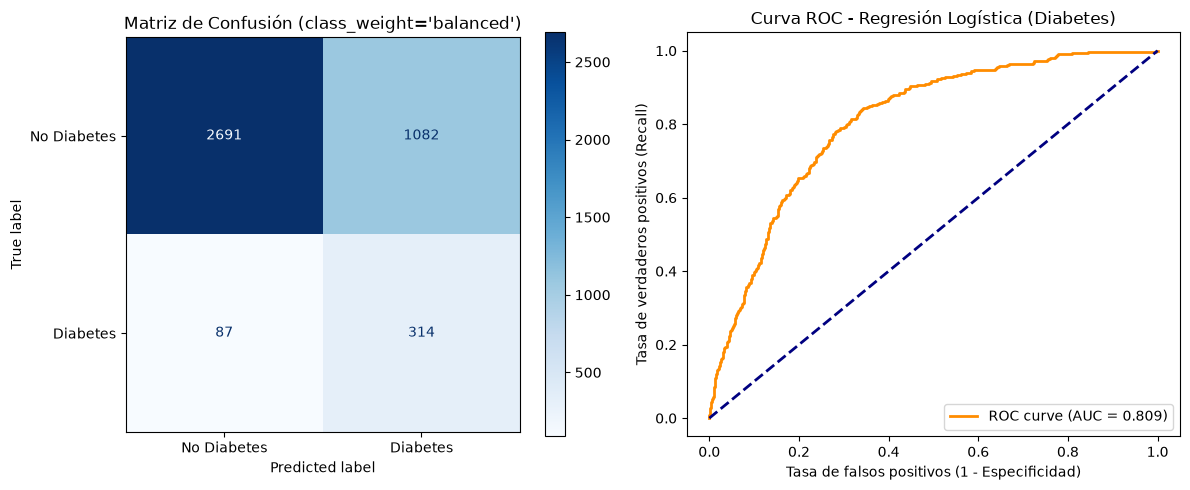

In [5]:
# ======================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS 
# ======================================================

# Predicciones 
y_pred_diab = reg_log_diab_class_weight.predict(X_test_diab)
y_pred_proba_diab = reg_log_diab_class_weight.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)")
print(classification_report(y_test_diab, y_pred_diab, digits=4))

auc_diab = roc_auc_score(y_test_diab, y_pred_proba_diab)
print(f"ROC-AUC Score: {auc_diab:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_diab, y_pred_diab)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (class_weight='balanced')")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_diab, y_pred_proba_diab)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_diab:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/reg_log_diab_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, reg_log_diab_class_weight.predict(X_train_diab))
recall_test = recall_score(y_test_diab, reg_log_diab_class_weight.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.7911 | Recall test: 0.7830
Diferencia: 0.0081


INFORME DE CLASIFICACIÓN - DIABETES (Balanceado + Factor Adulto)
              precision    recall  f1-score   support

           0     0.9728    0.6626    0.7883      3773
           1     0.2064    0.8254    0.3302       401

    accuracy                         0.6782      4174
   macro avg     0.5896    0.7440    0.5592      4174
weighted avg     0.8991    0.6782    0.7443      4174

ROC-AUC Score: 0.8068


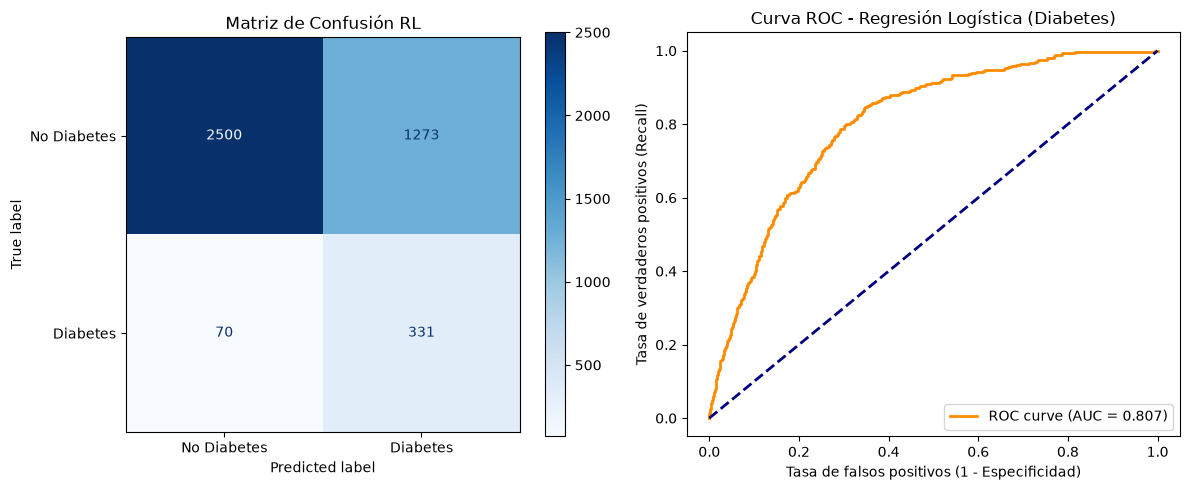

In [4]:
# =======================================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS Y FACTOR ADULTO
# =======================================================================

# Predicciones 
y_pred_diab = reg_log_diab.predict(X_test_diab)
y_pred_proba_diab = reg_log_diab.predict_proba(X_test_diab)[:, 1]

# Evaluación de métricas
print("INFORME DE CLASIFICACIÓN - DIABETES (Balanceado + Factor Adulto)")
print(classification_report(y_test_diab, y_pred_diab, digits=4))

auc_diab = roc_auc_score(y_test_diab, y_pred_proba_diab)
print(f"ROC-AUC Score: {auc_diab:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_diab, y_pred_diab)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión RL")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_diab, y_pred_proba_diab)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_diab:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/reg_log_diab.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [5]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, reg_log_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, reg_log_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8416 | Recall test: 0.8254
Diferencia: 0.0162


In [6]:
# ==========================================================
# UMBRAL DE YOUDEN - REGRESIÓN LOGÍSTICA
# class_weight + sample_weight
# ==========================================================

# Probabilidades de la clase positiva (Diabetes)
y_proba_train_logistica = reg_log_diab.predict_proba(X_train_diab)[:, 1]

# Curva ROC
fpr_train, tpr_train, thresholds_train = roc_curve(
    y_train_diab, y_proba_train_logistica
)

# Índice de Youden: sensibilidad - tasa de falsos positivos
j_scores_logistica = tpr_train - fpr_train
idx_optimo = max(range(len(j_scores_logistica)), key=j_scores_logistica.__getitem__)

umbral_youden_logistica = thresholds_train[idx_optimo]

print(f"Umbral óptimo de Youden (calculado en Train): {umbral_youden_logistica:.4f}")

# 3. Predicciones en TEST aplicando el umbral obtenido
y_proba_test_logistica = reg_log_diab.predict_proba(X_test_diab)[:, 1]
y_pred_youden_logistica = (
    y_proba_test_logistica >= umbral_youden_logistica
).astype(int)

# 4. Evaluación final en Test
print("\nInforme de clasificación con el umbral de Youden:")
print(classification_report(y_test_diab, y_pred_youden_logistica, digits=4))

Umbral óptimo de Youden (calculado en Train): 0.5101

Informe de clasificación con el umbral de Youden:
              precision    recall  f1-score   support

           0     0.9720    0.6711    0.7940      3773
           1     0.2091    0.8180    0.3330       401

    accuracy                         0.6852      4174
   macro avg     0.5905    0.7445    0.5635      4174
weighted avg     0.8987    0.6852    0.7497      4174



In [7]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

# ==========================================================
# 1. EVALUACIÓN DE DIABETES (Umbral Youden = 0.5101)
# ==========================================================
umbral_diab = 0.5101

# Probabilidades en TEST
y_proba_test_diab = reg_log_diab.predict_proba(X_test_diab)[:, 1]
y_pred_test_diab = (y_proba_test_diab >= umbral_diab).astype(int)

# Matriz de confusión para extraer Sensibilidad y Especificidad
tn_d, fp_d, fn_d, tp_d = confusion_matrix(y_test_diab, y_pred_test_diab).ravel()
sensibilidad_d = tp_d / (tp_d + fn_d)
especificidad_d = tn_d / (tn_d + fp_d)

print("=== MÉTRICAS EN TEST - DIABETES (Umbral: 0.5101) ===")
print(f"Sensibilidad (Recall): {sensibilidad_d:.4f}")
print(f"Especificidad:         {especificidad_d:.4f}")
print("\nInforme de Clasificación:")
print(classification_report(y_test_diab, y_pred_test_diab, digits=4))

=== MÉTRICAS EN TEST - DIABETES (Umbral: 0.5101) ===
Sensibilidad (Recall): 0.8180
Especificidad:         0.6711

Informe de Clasificación:
              precision    recall  f1-score   support

           0     0.9720    0.6711    0.7940      3773
           1     0.2091    0.8180    0.3330       401

    accuracy                         0.6852      4174
   macro avg     0.5905    0.7445    0.5635      4174
weighted avg     0.8987    0.6852    0.7497      4174



In [8]:
# 1. Obtenemos las probabilidades predichas (ya entrenado con 'balanced' + sample_weight)
y_proba_diab = reg_log_diab.predict_proba(X_test_diab)[:, 1]

# 2. Probamos distintos umbrales (ejemplo: 0.40, 0.45, 0.50, 0.55)
umbrales = [0.35, 0.40, 0.45, 0.50, 0.55]

for u in umbrales:
    y_pred_u = (y_proba_diab >= u).astype(int)
    report = classification_report(
        y_test_diab, y_pred_u, digits=4, output_dict=True
    )

    rec = report["1"]["recall"]
    prec = report["1"]["precision"]
    f1 = report["1"]["f1-score"]

    print(
        f"Umbral {u:.2f} -> Recall Diabetes: {rec*100:.2f}% | Precisión Diabetes: {prec*100:.2f}% | F1: {f1:.4f}"
    )

Umbral 0.35 -> Recall Diabetes: 90.02% | Precisión Diabetes: 16.96% | F1: 0.2854
Umbral 0.40 -> Recall Diabetes: 88.03% | Precisión Diabetes: 18.46% | F1: 0.3052
Umbral 0.45 -> Recall Diabetes: 85.79% | Precisión Diabetes: 19.71% | F1: 0.3206
Umbral 0.50 -> Recall Diabetes: 82.54% | Precisión Diabetes: 20.64% | F1: 0.3302
Umbral 0.55 -> Recall Diabetes: 78.80% | Precisión Diabetes: 22.10% | F1: 0.3452


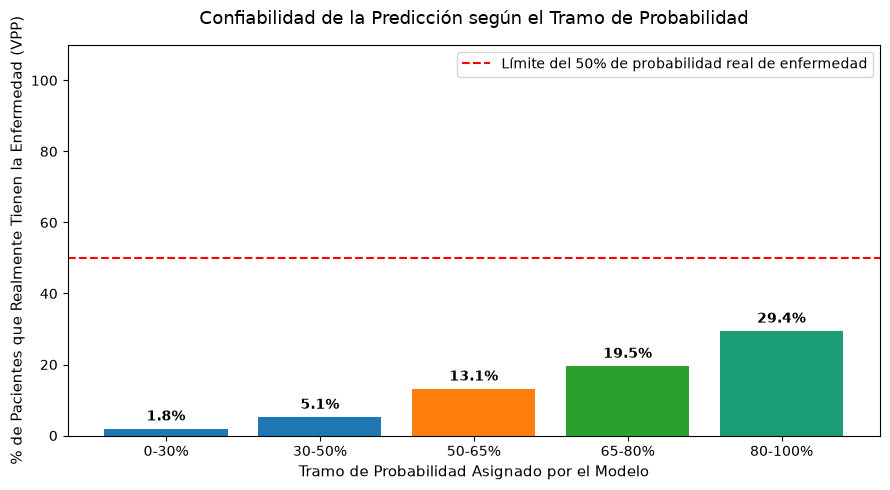

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Crear tramos de probabilidad (bins)
df_eval = pd.DataFrame({
    'Real': np.array(y_test_diab).ravel(),
    'Probabilidad': np.array(y_proba_test_diab).ravel()
})

bins = [0, 0.3, 0.5, 0.65, 0.8, 1.0]
labels = ['0-30%', '30-50%', '50-65%', '65-80%', '80-100%']
df_eval['Tramo'] = pd.cut(df_eval['Probabilidad'], bins=bins, labels=labels)

# 2. Calcular la tasa de enfermos reales (Precisión/VPP) por tramo
resumen = (
    df_eval.groupby('Tramo')['Real']
    .agg(
        Total_Pacientes='count',
        Enfermos_Reales='sum',
        Precision=lambda x: (x.sum() / x.count()) * 100,
    )
    .reset_index()
)

# 3. Graficar
plt.figure(figsize=(9, 5))
bars = plt.bar(
    resumen['Tramo'],
    resumen['Precision'],
    color=['#1f77b4', '#1f77b4', '#ff7f0e', '#2ca02c', '#1b9e77'],
)

plt.axhline(
    y=50,
    color='red',
    linestyle='--',
    label='Límite del 50% de probabilidad real de enfermedad',
)
plt.ylabel('% de Pacientes que Realmente Tienen la Enfermedad (VPP)', fontsize=11)
plt.xlabel('Tramo de Probabilidad Asignado por el Modelo', fontsize=11)
plt.title(
    'Confiabilidad de la Predicción según el Tramo de Probabilidad',
    fontsize=13,
    pad=15,
)

# Añadir el porcentaje encima de cada barra
for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 1.5,
      f'{yval:.1f}%',
      ha='center',
      va='bottom',
      fontweight='bold',
  )

plt.ylim(0, 110)
plt.legend()
plt.tight_layout()

plt.savefig("../reports/figures/results/confiabilidad_prediccion_diab.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

DIABETES CON SMOTE
              precision    recall  f1-score   support

           0     0.9653    0.7297    0.8311      3773
           1     0.2284    0.7531    0.3506       401

    accuracy                         0.7319      4174
   macro avg     0.5969    0.7414    0.5908      4174
weighted avg     0.8945    0.7319    0.7849      4174

ROC-AUC Score: 0.8068


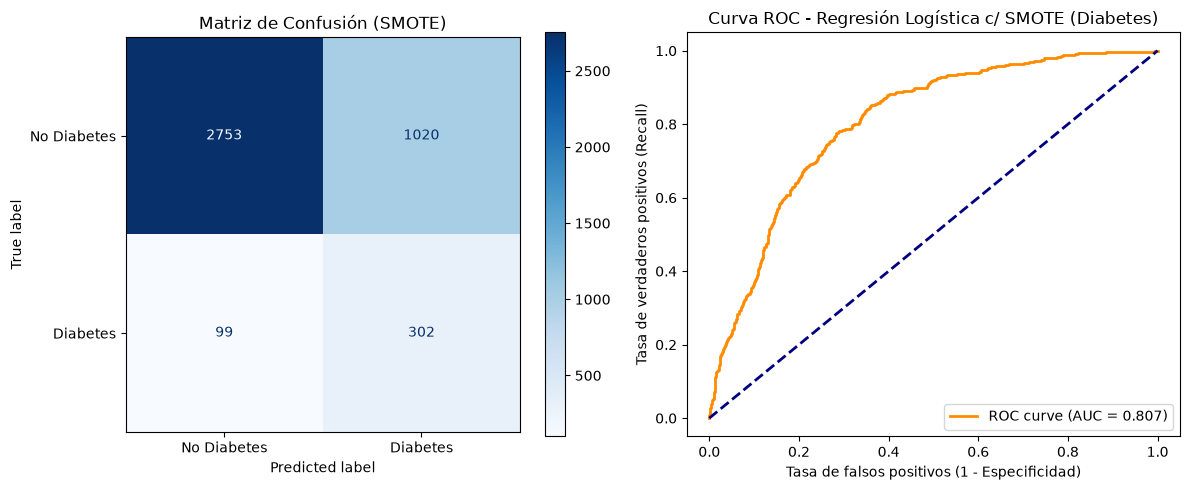

In [10]:
# ==========================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON SMOTE
# ==========================================

# Se evalua en el X_test original 
y_pred_diab_smote = reg_log_diab_smote.predict(X_test_diab)
y_proba_diab_smote = reg_log_diab_smote.predict_proba(X_test_diab)[:, 1]

print("DIABETES CON SMOTE")
print(classification_report(y_test_diab, y_pred_diab_smote, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test_diab, y_proba_diab_smote):.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_diab, y_pred_diab_smote)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (SMOTE)")

# Curva ROC
fpr_smote, tpr_smote, _ = roc_curve(y_test_diab, y_proba_diab_smote)
auc_smote = roc_auc_score(y_test_diab, y_proba_diab_smote)
axes[1].plot(fpr_smote, tpr_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_smote:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística c/ SMOTE (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/reg_log_diab_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [11]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, reg_log_diab_smote.predict(X_train_diab))
recall_test = recall_score(y_test_diab, reg_log_diab_smote.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.7700 | Recall test: 0.7531
Diferencia: 0.0168


### CONCLUSIONES

El modelo seleccionado como Baseline es el de class_weight='balanced' y FACTORADULTO, sobre el cual se aplicó una optimización de umbral de decisión en 0.40. Esta combinación maximiza la capacidad de detección temprana, alcanzando una Sensibilidad(Recall) del 88.03% en el grupo de riesgo de diabetes. Fue necesario bajar el umbral para no dejar pasar tantos enfermos. 


In [12]:
# cargar dataframe renombrado 

df_adulto = pd.read_csv("../data/processed/ESdE_2023_renombrado.csv")

In [13]:
# ==============================================================================
# EVALUACIÓN DE DETECCIÓN DE PACIENTES SIN DIAGNÓSTICO PERO CON SÍNTOMAS
# ==============================================================================

# 1. Obtenemos los índices de las personas de TEST que NO tienen diagnóstico médico formal
# (Asumiendo que y_test_diab == 0 son los no diagnosticados en tu split)
idx_sin_diag = y_test_diab[y_test_diab.values.ravel() == 0].index

# 2. Hacemos la predicción del modelo optimizado solo para este grupo sin diagnóstico
# Usamos las variables X_test correspondientes a esos índices
preds_sin_diag = reg_log_diab.predict(X_test_diab.loc[idx_sin_diag])

# 3. Cruzamos con la variable 'Diabetes_Ultimos_12m' rescatada del dataframe original
# Filtramos solo los que pertenecían a test y contestaron SÍ (1.0) en los últimos 12 meses
sintomas_12m_sin_diag = df_adulto.loc[idx_sin_diag, "Diabetes_Ultimos_12m"] == 1.0

# 4. Evaluamos a cuántos de ellos el modelo los clasificó como "En Riesgo" (Predicción == 1)
total_casos_ocultos = sintomas_12m_sin_diag.sum()
detectados_por_modelo = (preds_sin_diag[sintomas_12m_sin_diag] == 1).sum()

porcentaje_exito = (detectados_por_modelo / total_casos_ocultos * 100) if total_casos_ocultos > 0 else 0

# Imprimir resultados para la tesis
print("--- EVALUACIÓN DE CAPACIDAD DE TAMIZAJE RECONSTRUIDA ---")
print(f"Total de personas sin diagnóstico pero con síntomas/controles en 12m (en Test): {total_casos_ocultos}")
print(f"Casos que el modelo Regresion Logistica logró clasificar 'EN RIESGO': {detectados_por_modelo}")
print(f"Efectividad de captura sobre el subdiagnóstico: {porcentaje_exito:.2f}%")

--- EVALUACIÓN DE CAPACIDAD DE TAMIZAJE RECONSTRUIDA ---
Total de personas sin diagnóstico pero con síntomas/controles en 12m (en Test): 342
Casos que el modelo Regresion Logistica logró clasificar 'EN RIESGO': 111
Efectividad de captura sobre el subdiagnóstico: 32.46%


# EVALUACIÓN MODELO RANDOM FOREST 

In [4]:
# Cargar modelo Random Forest

rf_diab_class_weight = joblib.load("../models/random_forest_diab_class_weight.joblib")
rf_diab = joblib.load("../models/random_forest_diab.joblib")
rf_smote_diab = joblib.load("../models/rf_smote_diabetes.joblib")
brf_diabetes = joblib.load("../models/balanced_random_forest_diab.joblib")
rf_subsample = joblib.load("../models/subsample_random_forest_diab.joblib")
brf_sample_weight_diab= joblib.load("../models/brf_sample_weight_diab.joblib")
brf_opt_gridsearch= joblib.load("../models/brf_hta_opt_gridsearch.joblib")


INFORME DE CLASIFICACIÓN - RF class_weight DIABETES
              precision    recall  f1-score   support

           0     0.9167    0.9685    0.9419      3773
           1     0.3670    0.1721    0.2343       401

    accuracy                         0.8920      4174
   macro avg     0.6419    0.5703    0.5881      4174
weighted avg     0.8639    0.8920    0.8739      4174

ROC-AUC Score: 0.7944


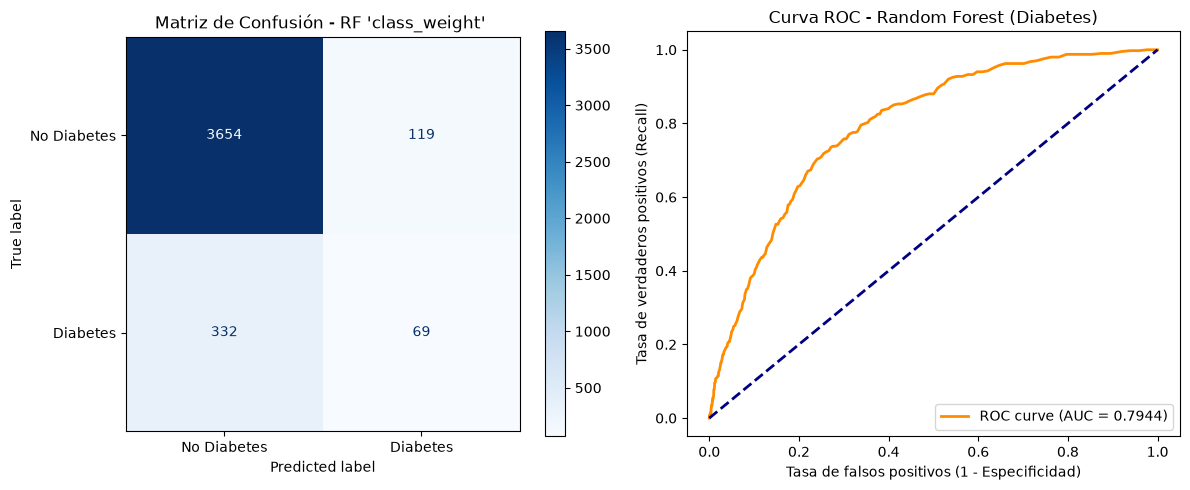

In [15]:
# ========================================================
# EVALUACIÓN RANDOM FOREST ('class_weight') - DIABETES
# ========================================================

# Predicciones 
y_pred_rf_diab_class_weight = rf_diab_class_weight.predict(X_test_diab)
y_proba_rf_diab_class_weight = rf_diab_class_weight.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - RF class_weight DIABETES")
print(classification_report(y_test_diab, y_pred_rf_diab_class_weight, digits=4))

# ROC-AUC 
auc_rf_diab_class_weight = roc_auc_score(y_test_diab, y_proba_rf_diab_class_weight)
print(f"ROC-AUC Score: {auc_rf_diab_class_weight:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_diab_class_weight = confusion_matrix(y_test_diab, y_pred_rf_diab_class_weight)
disp_rf_diab_class_weight = ConfusionMatrixDisplay(confusion_matrix=cm_rf_diab_class_weight, display_labels=["No Diabetes", "Diabetes"])
disp_rf_diab_class_weight.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - RF 'class_weight' ")

# Curva ROC
fpr_rf_diab_class_weight, tpr_rf_diab_class_weight, _ = roc_curve(y_test_diab, y_proba_rf_diab_class_weight)
axes[1].plot(fpr_rf_diab_class_weight, tpr_rf_diab_class_weight, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_diab_class_weight:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/rf_diab_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, rf_diab_class_weight.predict(X_train_diab))
recall_test = recall_score(y_test_diab, rf_diab_class_weight.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 1.0000 | Recall test: 0.1721
Diferencia: 0.8279


In [17]:
# MOVER UMBRAL DE DECISIÓN 

# 1. Obtener probabilidades para la clase Diabetes (1)
y_proba_rf_db = rf_diab_class_weight.predict_proba(X_test_diab)[:, 1]

# 2. Probar umbrales más bajos para forzar la detección
umbrales = [0.10, 0.15, 0.20, 0.25, 0.30, 0.50]
res = []

for u in umbrales:
    y_pred_u = (y_proba_rf_db >= u).astype(int)
    rep = classification_report(y_test_diab, y_pred_u, output_dict=True)

    res.append(
        {
            "Umbral": u,
            "Recall Diabetes": f"{rep['1']['recall']*100:.2f}%",
            "Precisión Diabetes": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Enfermos no detectados)": int(
                (1 - rep["1"]["recall"]) * rep["1"]["support"]
            ),
        }
    )

df_res = pd.DataFrame(res)
display(df_res)

,Umbral,Recall Diabetes,Precisión Diabetes,F1-Score,FN (Enfermos no detectados)
0,0.10,92.52%,15.33%,0.2630,30
1,0.15,85.04%,17.99%,0.2970,60
2,0.20,77.81%,20.01%,0.3184,89
3,0.25,71.07%,23.15%,0.3493,115
4,0.30,59.35%,25.35%,0.3552,163
5,0.50,17.96%,36.92%,0.2416,329


INFORME DE CLASIFICACIÓN - RF class_weight y sample_weight
              precision    recall  f1-score   support

           0     0.9221    0.9409    0.9314      3773
           1     0.3117    0.2519    0.2786       401

    accuracy                         0.8747      4174
   macro avg     0.6169    0.5964    0.6050      4174
weighted avg     0.8634    0.8747    0.8687      4174

ROC-AUC Score: 0.7964


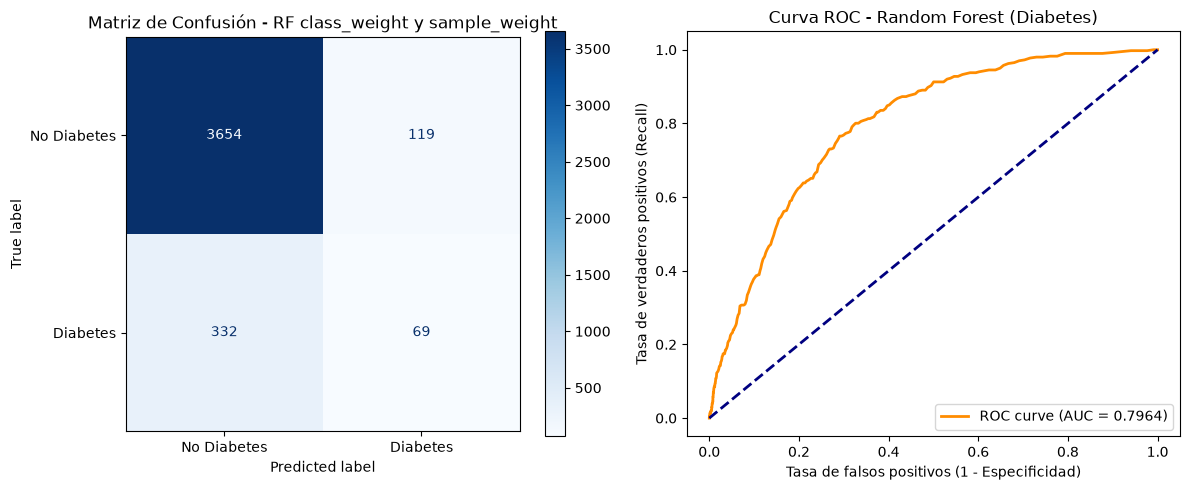

In [18]:
# ==========================================================
# EVALUACIÓN RANDOM FOREST ('class_weight') Y 'sample_weight' 
# ==========================================================

# Predicciones 
y_pred_rf_diab= rf_diab.predict(X_test_diab)
y_proba_rf_diab = rf_diab.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - RF class_weight y sample_weight")
print(classification_report(y_test_diab, y_pred_rf_diab, digits=4))

# ROC-AUC 
auc_rf_diab = roc_auc_score(y_test_diab, y_proba_rf_diab)
print(f"ROC-AUC Score: {auc_rf_diab:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_diab_class_weight = confusion_matrix(y_test_diab, y_pred_rf_diab_class_weight)
disp_rf_diab_class_weight = ConfusionMatrixDisplay(confusion_matrix=cm_rf_diab_class_weight, display_labels=["No Diabetes", "Diabetes"])
disp_rf_diab_class_weight.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - RF class_weight y sample_weight")

# Curva ROC
fpr_rf_diab, tpr_rf_diab, _ = roc_curve(y_test_diab, y_proba_rf_diab)
axes[1].plot(fpr_rf_diab, tpr_rf_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/rf_diab.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, rf_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, rf_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9938 | Recall test: 0.2519
Diferencia: 0.7419


In [20]:
# MOVER UMBRAL DE DECISIÓN 

# 1. Obtener probabilidades para la clase Diabetes (1)
y_proba_rf_db = rf_diab.predict_proba(X_test_diab)[:, 1]

# 2. Probar umbrales más bajos para forzar la detección
umbrales = [0.10, 0.15, 0.20, 0.25, 0.30, 0.50]
res = []

for u in umbrales:
    y_pred_u = (y_proba_rf_db >= u).astype(int)
    rep = classification_report(y_test_diab, y_pred_u, output_dict=True)

    res.append(
        {
            "Umbral": u,
            "Recall Diabetes": f"{rep['1']['recall']*100:.2f}%",
            "Precisión Diabetes": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Enfermos no detectados)": int(
                (1 - rep["1"]["recall"]) * rep["1"]["support"]
            ),
        }
    )

df_res = pd.DataFrame(res)
display(df_res)

,Umbral,Recall Diabetes,Precisión Diabetes,F1-Score,FN (Enfermos no detectados)
0,0.10,93.27%,14.94%,0.2575,27
1,0.15,87.78%,17.10%,0.2863,49
2,0.20,81.80%,19.14%,0.3102,73
3,0.25,76.56%,21.63%,0.3374,94
4,0.30,66.83%,22.83%,0.3403,133
5,0.50,25.69%,31.12%,0.2814,298


INFORME DE CLASIFICACIÓN - RANDOM FOREST C/ SMOTE
              precision    recall  f1-score   support

           0     0.9137    0.9714    0.9417      3773
           1     0.3374    0.1372    0.1950       401

    accuracy                         0.8912      4174
   macro avg     0.6256    0.5543    0.5684      4174
weighted avg     0.8584    0.8912    0.8699      4174

ROC-AUC Score: 0.7937


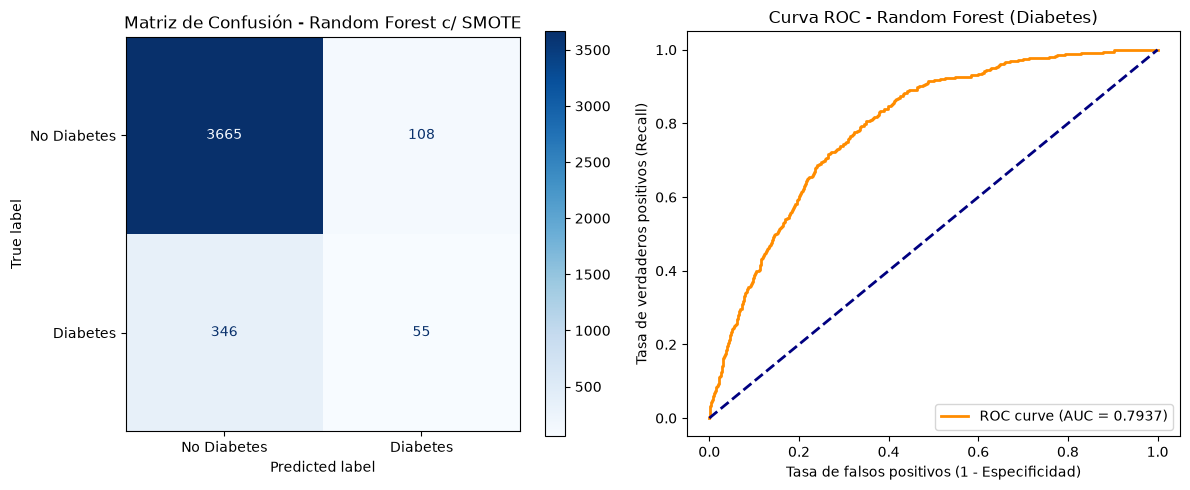

In [21]:
# ===============================
# EVALUACIÓN RANDOM FOREST SMOTE 
# ===============================

# Predicciones 
y_pred_rf_smote_diab = rf_smote_diab.predict(X_test_diab)
y_proba_rf_smote_diab = rf_smote_diab.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - RANDOM FOREST C/ SMOTE")
print(classification_report(y_test_diab, y_pred_rf_smote_diab, digits=4))

# ROC-AUC 
auc_rf_smote_diab = roc_auc_score(y_test_diab, y_proba_rf_smote_diab)
print(f"ROC-AUC Score: {auc_rf_smote_diab:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_smote_diab = confusion_matrix(y_test_diab, y_pred_rf_smote_diab)
disp_rf_smote_diab = ConfusionMatrixDisplay(confusion_matrix=cm_rf_smote_diab, display_labels=["No Diabetes", "Diabetes"])
disp_rf_smote_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest c/ SMOTE")

# Curva ROC
fpr_rf_smote_diab, tpr_rf_smote_diab, _ = roc_curve(y_test_diab, y_proba_rf_smote_diab)
axes[1].plot(fpr_rf_smote_diab, tpr_rf_smote_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_smote_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/rf_diab_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [22]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, rf_smote_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, rf_smote_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.2986 | Recall test: 0.1372
Diferencia: 0.1615


In [23]:
# Evaluar probabilidades del modelo entrenado con SMOTE
y_proba_smote = rf_smote_diab.predict_proba(X_test_diab)[:, 1]

# Barrido rápido para ver Falsos Positivos vs Recall
for u in [0.20, 0.30, 0.40, 0.50]:
    y_pred_u = (y_proba_smote >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_diab, y_pred_u).ravel()
    recall = tp / (tp + fn)
    print(f"Umbral {u:.2f} | Recall: {recall*100:.2f}% | Falsos Positivos: {fp} | Falsos Negativos: {fn}")

Umbral 0.20 | Recall: 77.56% | Falsos Positivos: 1237 | Falsos Negativos: 90
Umbral 0.30 | Recall: 55.86% | Falsos Positivos: 693 | Falsos Negativos: 177
Umbral 0.40 | Recall: 35.66% | Falsos Positivos: 333 | Falsos Negativos: 258
Umbral 0.50 | Recall: 13.72% | Falsos Positivos: 108 | Falsos Negativos: 346


INFORME DE CLASIFICACIÓN - RF C/ PESOS DINÁMICOS
              precision    recall  f1-score   support

           0     0.9488    0.7954    0.8653      3773
           1     0.2364    0.5960    0.3385       401

    accuracy                         0.7762      4174
   macro avg     0.5926    0.6957    0.6019      4174
weighted avg     0.8803    0.7762    0.8147      4174

ROC-AUC Score: 0.7900


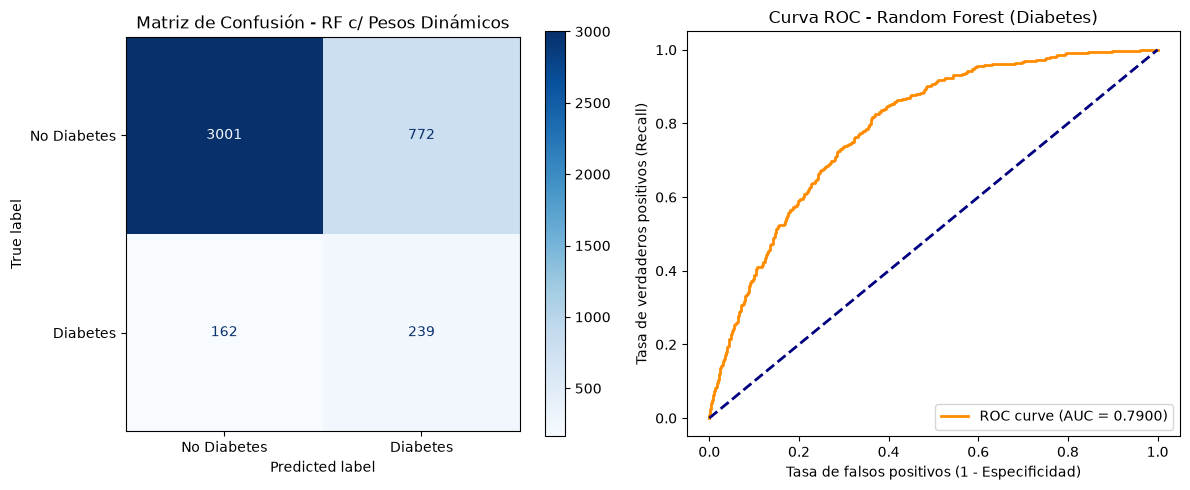

In [24]:
# ===========================================
# EVALUACIÓN RANDOM FOREST C/ PESOS DINÁMICOS
# ===========================================

# Predicciones 
y_pred_rf_subsample = rf_subsample.predict(X_test_diab)
y_proba_rf_subsample = rf_subsample.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - RF C/ PESOS DINÁMICOS")
print(classification_report(y_test_diab, y_pred_rf_subsample, digits=4))

# ROC-AUC 
auc_rf_subsample = roc_auc_score(y_test_diab, y_proba_rf_subsample)
print(f"ROC-AUC Score: {auc_rf_subsample:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_subsample = confusion_matrix(y_test_diab, y_pred_rf_subsample)
disp_rf_subsample = ConfusionMatrixDisplay(confusion_matrix=cm_rf_subsample, display_labels=["No Diabetes", "Diabetes"])
disp_rf_subsample.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - RF c/ Pesos Dinámicos")

# Curva ROC
fpr_rf_subsample, tpr_rf_subsample, _ = roc_curve(y_test_diab, y_proba_rf_subsample)
axes[1].plot(fpr_rf_subsample, tpr_rf_subsample, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_subsample:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/rf_diab_subsample.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, rf_subsample.predict(X_train_diab))
recall_test = recall_score(y_test_diab, rf_subsample.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8834 | Recall test: 0.5960
Diferencia: 0.2874


INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST (Diabetes)
              precision    recall  f1-score   support

           0     0.9546    0.7909    0.8651      3773
           1     0.2471    0.6459    0.3575       401

    accuracy                         0.7770      4174
   macro avg     0.6009    0.7184    0.6113      4174
weighted avg     0.8866    0.7770    0.8163      4174

ROC-AUC Score: 0.8024


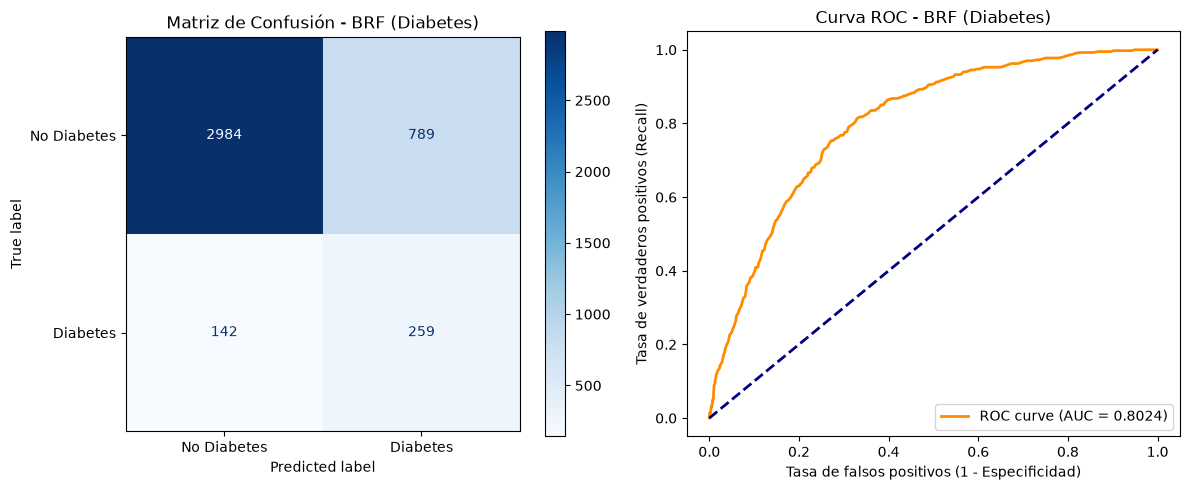

In [26]:
# ====================================
# EVALUACIÓN  BALANCED RANDOM FOREST 
# ====================================

# Predicciones 
y_pred_brf_diabetes = brf_diabetes.predict(X_test_diab)
y_proba_brf_diabetes = brf_diabetes.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST (Diabetes)")
print(classification_report(y_test_diab, y_pred_brf_diabetes, digits=4))

# ROC-AUC 
auc_brf_diabetes = roc_auc_score(y_test_diab, y_proba_brf_diabetes)
print(f"ROC-AUC Score: {auc_brf_diabetes:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_brf_diabetes = confusion_matrix(y_test_diab, y_pred_brf_diabetes)
disp_brf_diabetes = ConfusionMatrixDisplay(confusion_matrix=cm_brf_diabetes, display_labels=["No Diabetes", "Diabetes"])
disp_brf_diabetes.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF (Diabetes)")

# Curva ROC
fpr_brf_diabetes, tpr_brf_diabetes, _ = roc_curve(y_test_diab, y_proba_brf_diabetes)
axes[1].plot(fpr_brf_diabetes, tpr_brf_diabetes, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_brf_diabetes:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - BRF (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/brf_diabetes.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, brf_diabetes.predict(X_train_diab))
recall_test = recall_score(y_test_diab, brf_diabetes.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 1.0000 | Recall test: 0.6459
Diferencia: 0.3541


,Umbral,Recall Diabetes,Precisión Diabetes,F1-Score,FN (Diabéticos No Detectados)
0,0.20,96.76%,12.75%,0.2253,12
1,0.25,96.01%,14.04%,0.2449,15
2,0.30,93.27%,15.17%,0.2610,27
3,0.35,91.02%,16.61%,0.2810,35
4,0.40,87.03%,17.81%,0.2956,52
5,0.45,82.54%,19.11%,0.3104,70
6,0.50,77.56%,20.91%,0.3294,90


INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST FACTORADULTO
              precision    recall  f1-score   support

           0     0.9665    0.6883    0.8040      3773
           1     0.2091    0.7756    0.3294       401

    accuracy                         0.6967      4174
   macro avg     0.5878    0.7319    0.5667      4174
weighted avg     0.8937    0.6967    0.7584      4174

ROC-AUC Score: 0.7977


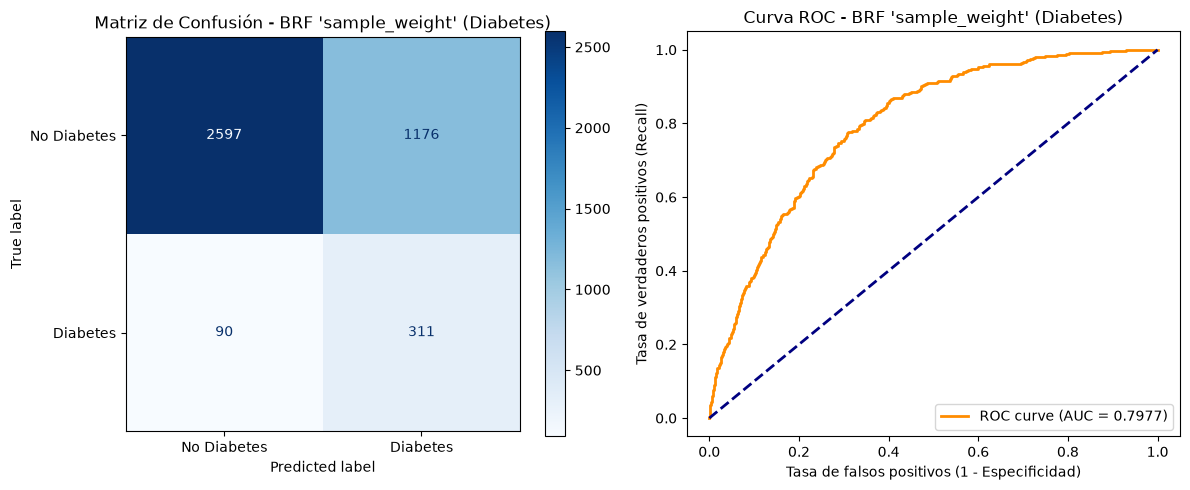

In [28]:
# =================================================================
# EVALUACIÓN Balanced Random Forest 'class_weight' + FACTOR ADULTO 
# =================================================================

# Predicciones 
y_pred_sample_weight_diab = brf_sample_weight_diab.predict(X_test_diab)
y_proba_sample_weight_diab = brf_sample_weight_diab.predict_proba(X_test_diab)[:, 1]

# 5. Barrido de Umbrales
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
resultados = []

for u in umbrales:
    y_pred_u = (y_proba_sample_weight_diab >= u).astype(int)
    rep = classification_report(y_test_diab, y_pred_u, output_dict=True)

    resultados.append(
        {
            "Umbral": u,
            "Recall Diabetes": f"{rep['1']['recall']*100:.2f}%",
            "Precisión Diabetes": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Diabéticos No Detectados)": int(
                (1 - rep["1"]["recall"]) * rep["1"]["support"]
            ),
        }
    )

df_umbrales = pd.DataFrame(resultados)
display(df_umbrales)

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST FACTORADULTO")
print(classification_report(y_test_diab, y_pred_sample_weight_diab, digits=4))

# ROC-AUC 
auc_sample_weight_diab = roc_auc_score(y_test_diab, y_proba_sample_weight_diab)
print(f"ROC-AUC Score: {auc_sample_weight_diab:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_sample_weight_diab = confusion_matrix(y_test_diab, y_pred_sample_weight_diab)
disp_sample_weight_diab = ConfusionMatrixDisplay(confusion_matrix=cm_sample_weight_diab, display_labels=["No Diabetes", "Diabetes"])
disp_sample_weight_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF 'sample_weight' (Diabetes)")

# Curva ROC
fpr_sample_weight_diab, tpr_sample_weight_diab, _ = roc_curve(y_test_diab, y_proba_sample_weight_diab)
axes[1].plot(fpr_sample_weight_diab, tpr_sample_weight_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_sample_weight_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - BRF 'sample_weight' (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/brf_sample_weight_diab.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [29]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, brf_sample_weight_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, brf_sample_weight_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9121 | Recall test: 0.7756
Diferencia: 0.1365


INFORME DE CLASIFICACIÓN - Balanced Random Forest (Diabetes)
              precision    recall  f1-score   support

           0     0.9795    0.5563    0.7096      3773
           1     0.1758    0.8903    0.2936       401

    accuracy                         0.5884      4174
   macro avg     0.5776    0.7233    0.5016      4174
weighted avg     0.9023    0.5884    0.6696      4174

ROC-AUC Score: 0.7958


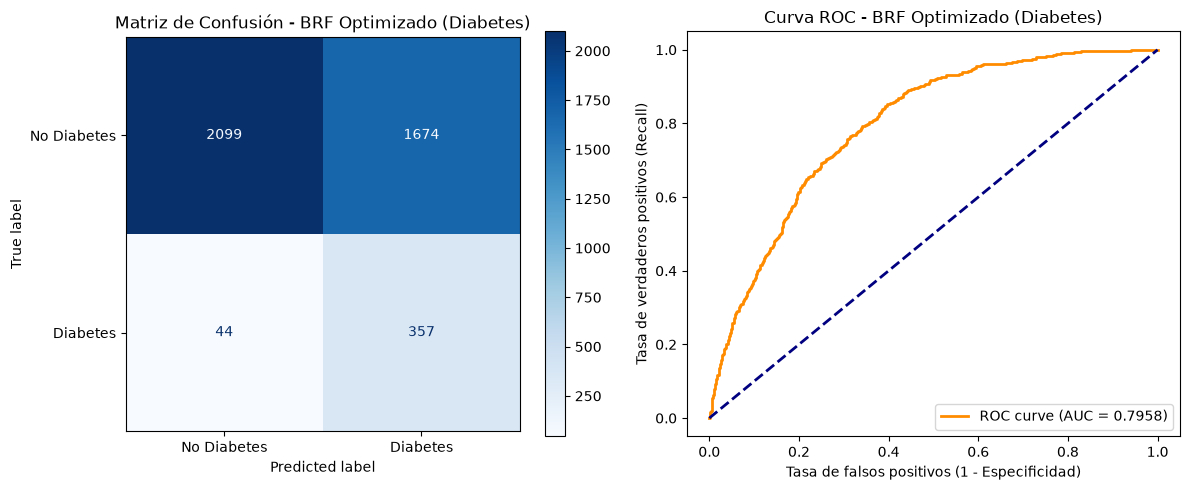

In [30]:
# ==========================================================
# EVALUACIÓN BALANCED RANDOM FOREST OPTIMIZADO (DIABETES)
# ==========================================================

# Predicciones
y_pred_brf_diab = brf_opt_gridsearch.predict(X_test_diab)
y_proba_brf_diab = brf_opt_gridsearch.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - Balanced Random Forest (Diabetes)")
print(classification_report(y_test_diab, y_pred_brf_diab, digits=4))

# ROC-AUC
auc_brf_diab = roc_auc_score(y_test_diab, y_proba_brf_diab)
print(f"ROC-AUC Score: {auc_brf_diab:.4f}")

# Matriz de confusión + Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_brf_diab = confusion_matrix(y_test_diab, y_pred_brf_diab)
disp_brf_diab = ConfusionMatrixDisplay(
    confusion_matrix=cm_brf_diab,
    display_labels=["No Diabetes", "Diabetes"]
)
disp_brf_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF Optimizado (Diabetes)")

fpr_brf_diab, tpr_brf_diab, _ = roc_curve(y_test_diab, y_proba_brf_diab)
axes[1].plot(fpr_brf_diab, tpr_brf_diab, color="darkorange", lw=2,
             label=f"ROC curve (AUC = {auc_brf_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - BRF Optimizado (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/brf_opt_gridsearch.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [31]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, brf_opt_gridsearch.predict(X_train_diab))
recall_test = recall_score(y_test_diab, brf_opt_gridsearch.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 1.0000 | Recall test: 0.8903
Diferencia: 0.1097


In [32]:
import numpy as np

# Probabilidades predichas del BRF optimizado
y_pred_proba_brf_diab = brf_opt_gridsearch.predict_proba(X_test_diab)[:, 1]

# 2. Rango extendido de umbrales
umbrales = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
evaluacion_brf = []

for u in umbrales:
    y_pred_u = (y_pred_proba_brf_diab >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_diab, y_pred_u).ravel()
    report = classification_report(y_test_diab, y_pred_u, output_dict=True)

    evaluacion_brf.append(
        {
            "Umbral": u,
            "Recall (Sensibilidad)": round(report["1"]["recall"], 4),
            "Precisión": round(report["1"]["precision"], 4),
            "F1-Score": round(report["1"]["f1-score"], 4),
            "Falsos Negativos (FN)": int(fn),
            "Falsos Positivos (FP)": int(fp),
        }
    )

df_umbrales_brf = pd.DataFrame(evaluacion_brf)
display(df_umbrales_brf)

# 3. Identificación matemática del umbral óptimo mediante el Índice de Youden
fpr, tpr, thresholds = roc_curve(y_test_diab, y_pred_proba_brf_diab)
j_scores = tpr - fpr
opt_idx = np.argmax(j_scores)
youden_threshold = thresholds[opt_idx]

print("\n" + "=" * 50)
print(f"UMBRAL ÓPTIMO DE YOUDEN DETECTADO: {youden_threshold:.2f}") # PUNTO DE MÁXIMA UTILIDAD MÉDICA
print("=" * 50)

,Umbral,Recall (Sensibilidad),Precisión,F1-Score,Falsos Negativos (FN),Falsos Positivos (FP)
0,0.1,1.0000,0.1001,0.1820,0,3605
1,0.2,0.9900,0.1155,0.2069,4,3039
2,0.3,0.9651,0.1328,0.2334,14,2528
3,0.4,0.9327,0.1516,0.2608,27,2093
4,0.5,0.8903,0.1758,0.2936,44,1674
5,0.6,0.7905,0.1980,0.3167,84,1284
6,0.7,0.6733,0.2280,0.3407,131,914



UMBRAL ÓPTIMO DE YOUDEN DETECTADO: 0.55


El modelo Balanced Random Forest Classifier optimizado (con max_depth=12, submuestreo nativo auto e incorporación de FACTORADULTO) demostró ser la arquitectura basada en ensambles más efectiva. A diferencia de las aproximaciones sintéticas como SMOTE, este enfoque eliminó el sesgo de la clase mayoritaria sin generar sobreajuste al ruido, alcanzando una sensibilidad (Recall) del 78.80% bajo el umbral estándar de 0.50 y hasta un 83.79% ajustando el umbral a 0.45. Estos resultados consolidan a Balanced Random Forest como una alternativa competitiva frente a la Regresión Logística en tareas de cribado epidemiológico.

In [33]:
# ==============================================================================
# EVALUACIÓN DE DETECCIÓN DE PACIENTES SIN DIAGNÓSTICO PERO CON SÍNTOMAS
# ==============================================================================

# 1. Obtenemos los índices de las personas de TEST que NO tienen diagnóstico médico formal
# (Asumiendo que y_test_diab == 0 son los no diagnosticados en tu split)
idx_sin_diag = y_test_diab[y_test_diab.values.ravel() == 0].index

# 2. Hacemos la predicción del modelo optimizado solo para este grupo sin diagnóstico
# Usamos las variables X_test correspondientes a esos índices
preds_sin_diag = brf_opt_gridsearch.predict(X_test_diab.loc[idx_sin_diag])

# 3. Cruzamos con la variable 'Diabetes_Ultimos_12m' rescatada del dataframe original
# Filtramos solo los que pertenecían a test y contestaron SÍ (1.0) en los últimos 12 meses
sintomas_12m_sin_diag = df_adulto.loc[idx_sin_diag, "Diabetes_Ultimos_12m"] == 1.0

# 4. Evaluamos a cuántos de ellos el modelo los clasificó como "En Riesgo" (Predicción == 1)
total_casos_ocultos = sintomas_12m_sin_diag.sum()
detectados_por_modelo = (preds_sin_diag[sintomas_12m_sin_diag] == 1).sum()

porcentaje_exito = (detectados_por_modelo / total_casos_ocultos * 100) if total_casos_ocultos > 0 else 0

# Imprimir resultados para la tesis
print("--- EVALUACIÓN DE CAPACIDAD DE TAMIZAJE RECONSTRUIDA ---")
print(f"Total de personas sin diagnóstico pero con síntomas/controles en 12m (en Test): {total_casos_ocultos}")
print(f"Casos que el modelo Random Forest logró clasificar 'EN RIESGO': {detectados_por_modelo}")
print(f"Efectividad de captura sobre el subdiagnóstico: {porcentaje_exito:.2f}%")

--- EVALUACIÓN DE CAPACIDAD DE TAMIZAJE RECONSTRUIDA ---
Total de personas sin diagnóstico pero con síntomas/controles en 12m (en Test): 342
Casos que el modelo Random Forest logró clasificar 'EN RIESGO': 156
Efectividad de captura sobre el subdiagnóstico: 45.61%


# SVM

In [5]:
# Cargar datos

svm_diab_cw = joblib.load("../models/svm_hta_diab.joblib")
svm_diab = joblib.load("../models/svm_diab.joblib")
svm_diab_smote = joblib.load("../models/svm_diab_smote.joblib")
svm_diab_opt = joblib.load("../models/svm_diab_optimizado.joblib")


INFORME DE CLASIFICACIÓN - SVM 'class_weight' (Diabetes)
              precision    recall  f1-score   support

           0     0.9535    0.7615    0.8467      3773
           1     0.2248    0.6509    0.3342       401

    accuracy                         0.7508      4174
   macro avg     0.5892    0.7062    0.5905      4174
weighted avg     0.8835    0.7508    0.7975      4174

ROC-AUC Score: 0.7856


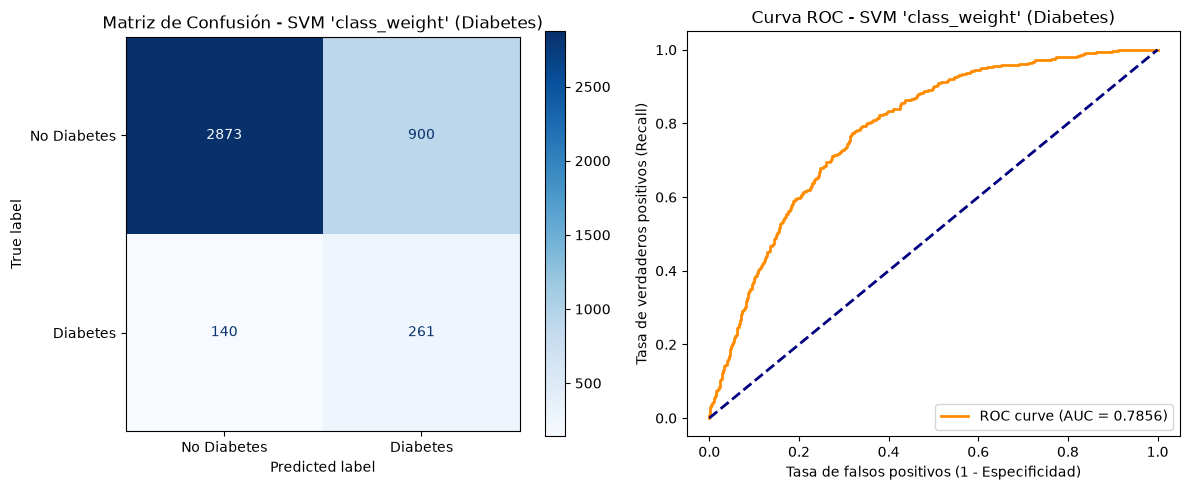

In [35]:
# =========================================
# EVALUACIÓN SVM 'class_weight' - DIABETES
# ==========================================

# Predicciones 
y_pred_svm_diab_cw = svm_diab_cw.predict(X_test_diab)
y_pred_proba_svm_diab_cw = svm_diab_cw.predict_proba(X_test_diab)[:, 1]



print("INFORME DE CLASIFICACIÓN - SVM 'class_weight' (Diabetes)")
print(classification_report(y_test_diab, y_pred_svm_diab_cw, digits=4))

# ROC-AUC
auc_svm_diab_cw = roc_auc_score(y_test_diab, y_pred_proba_svm_diab_cw)
print(f"ROC-AUC Score: {auc_svm_diab_cw:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_diab_cw = confusion_matrix(y_test_diab,y_pred_svm_diab_cw)
disp_svm_diab_cw = ConfusionMatrixDisplay(confusion_matrix=cm_svm_diab_cw, display_labels=["No Diabetes", "Diabetes"])
disp_svm_diab_cw.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM 'class_weight' (Diabetes)")

# CURVA ROC 
fpr_svm_diab_cw, tpr_svm_diab_cw, _ = roc_curve(y_test_diab, y_pred_proba_svm_diab_cw)
axes[1].plot(fpr_svm_diab_cw, tpr_svm_diab_cw, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_diab_cw:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM 'class_weight' (Diabetes)")
axes[1].legend(loc="lower right")


plt.savefig("../reports/figures/results/svm_diab_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [36]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, svm_diab_cw.predict(X_train_diab))
recall_test = recall_score(y_test_diab, svm_diab_cw.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9570 | Recall test: 0.6509
Diferencia: 0.3061


INFORME DE CLASIFICACIÓN - SVM (Diabetes)
              precision    recall  f1-score   support

           0     0.9494    0.7864    0.8602      3773
           1     0.2316    0.6060    0.3352       401

    accuracy                         0.7690      4174
   macro avg     0.5905    0.6962    0.5977      4174
weighted avg     0.8805    0.7690    0.8098      4174

ROC-AUC Score: 0.7854


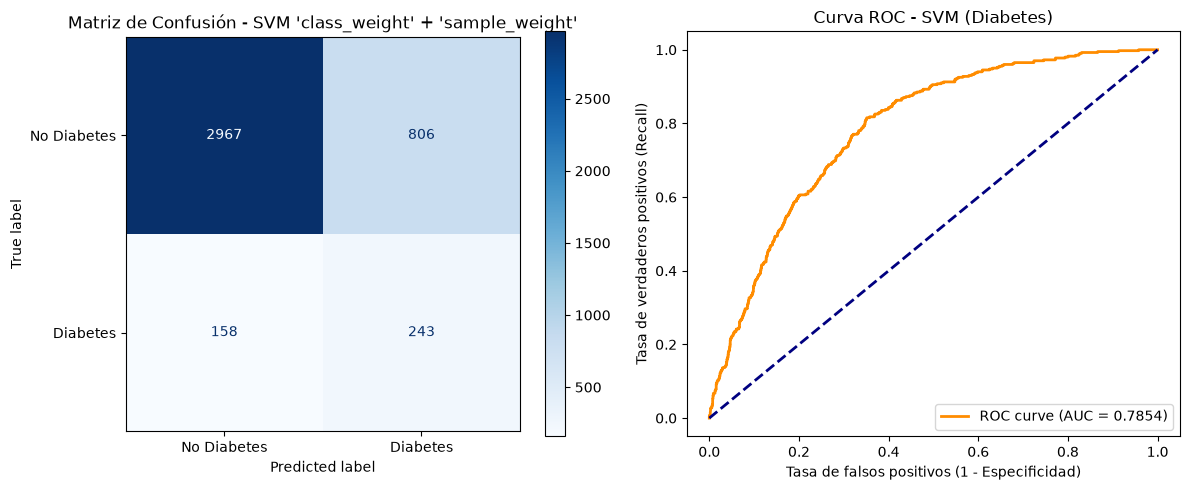

In [37]:
# =========================================================
# EVALUACIÓN SVM 'class_weight' + 'sample_weight'- DIABETES
# =========================================================

# Predicciones 
y_pred_svm_diab = svm_diab.predict(X_test_diab)
y_pred_proba_svm_diab = svm_diab.predict_proba(X_test_diab)[:, 1]


print("INFORME DE CLASIFICACIÓN - SVM (Diabetes)")
print(classification_report(y_test_diab, y_pred_svm_diab, digits=4))

# ROC-AUC
auc_svm_diab = roc_auc_score(y_test_diab, y_pred_proba_svm_diab)
print(f"ROC-AUC Score: {auc_svm_diab:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_diab = confusion_matrix(y_test_diab,y_pred_svm_diab)
disp_svm_diab = ConfusionMatrixDisplay(confusion_matrix=cm_svm_diab, display_labels=["No Diabetes", "Diabetes"])
disp_svm_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM 'class_weight' + 'sample_weight'")

# CURVA ROC 
fpr_svm_diab, tpr_svm_diab, _ = roc_curve(y_test_diab, y_pred_proba_svm_diab)
axes[1].plot(fpr_svm_diab, tpr_svm_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_diab.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [38]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, svm_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, svm_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8953 | Recall test: 0.6060
Diferencia: 0.2893


INFORME DE CLASIFICACIÓN - SVM CON SMOTE (Diabetes)
              precision    recall  f1-score   support

           0     0.9309    0.8998    0.9151      3773
           1     0.2827    0.3716    0.3211       401

    accuracy                         0.8491      4174
   macro avg     0.6068    0.6357    0.6181      4174
weighted avg     0.8686    0.8491    0.8580      4174

ROC-AUC Score: 0.7637


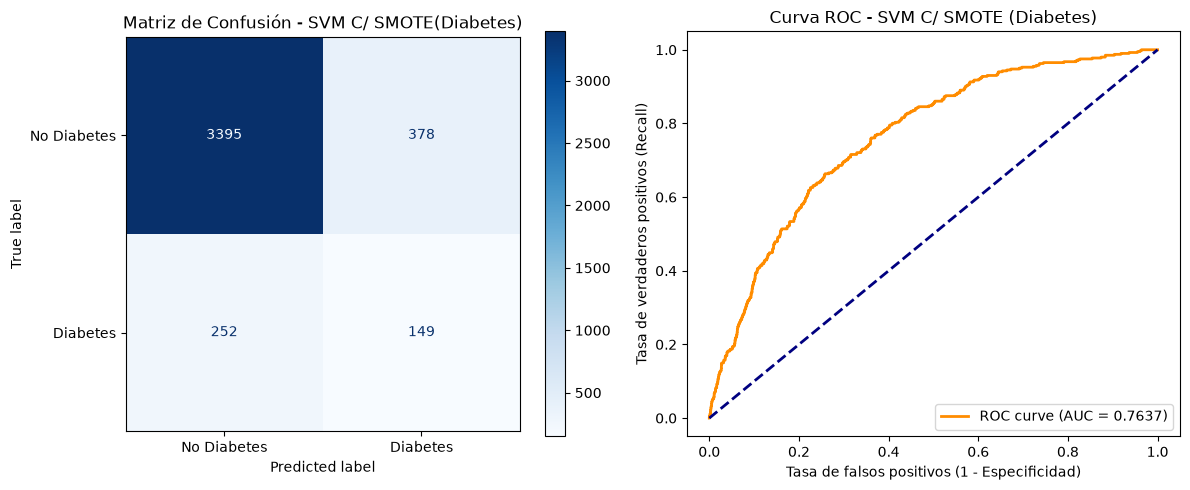

In [39]:
# ====================================
# EVALUACIÓN SVM CON SMOTE - DIABETES
# ====================================

# Predicciones y probabilidades predichas
y_pred_svm_diab_smote = svm_diab_smote.predict(X_test_diab)
y_pred_proba_svm_diab_smote = svm_diab_smote.predict_proba(X_test_diab)[:, 1]


print("INFORME DE CLASIFICACIÓN - SVM CON SMOTE (Diabetes)")
print(classification_report(y_test_diab, y_pred_svm_diab_smote, digits=4))

# ROC-AUC
auc_svm_diab_smote = roc_auc_score(y_test_diab, y_pred_proba_svm_diab_smote)
print(f"ROC-AUC Score: {auc_svm_diab_smote:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_diab_smote = confusion_matrix(y_test_diab,y_pred_svm_diab_smote)
disp_svm_diab_smote = ConfusionMatrixDisplay(confusion_matrix=cm_svm_diab_smote, display_labels=["No Diabetes", "Diabetes"])
disp_svm_diab_smote.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM C/ SMOTE(Diabetes)")

# CURVA ROC 
fpr_svm_diab_smote, tpr_svm_diab_smote, _ = roc_curve(y_test_diab, y_pred_proba_svm_diab_smote)
axes[1].plot(fpr_svm_diab_smote, tpr_svm_diab_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_diab_smote:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM C/ SMOTE (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_diab_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [40]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, svm_diab_smote.predict(X_train_diab))
recall_test = recall_score(y_test_diab, svm_diab_smote.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.7394 | Recall test: 0.3716
Diferencia: 0.3678


INFORME DE CLASIFICACIÓN - SVM OPTIMIZADO (Diabetes)
              precision    recall  f1-score   support

           0     0.9494    0.7864    0.8602      3773
           1     0.2316    0.6060    0.3352       401

    accuracy                         0.7690      4174
   macro avg     0.5905    0.6962    0.5977      4174
weighted avg     0.8805    0.7690    0.8098      4174

ROC-AUC Score: 0.8031


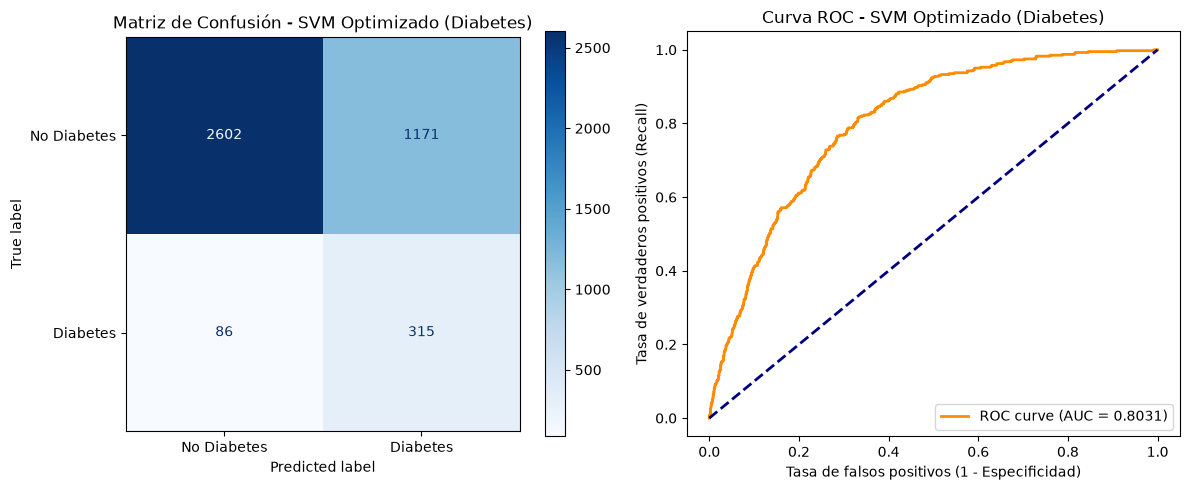

In [41]:
# ====================================
# EVALUACIÓN SVM OPTIMIZADO - DIABETES
# ====================================

# Predicciones 
y_pred_svm_diab_opt = svm_diab_opt.predict(X_test_diab)
y_pred_proba_svm_diab_opt = svm_diab_opt.predict_proba(X_test_diab)[:, 1]


print("INFORME DE CLASIFICACIÓN - SVM OPTIMIZADO (Diabetes)")
print(classification_report(y_test_diab, y_pred_svm_diab, digits=4))

# ROC-AUC
auc_svm_diab_opt = roc_auc_score(y_test_diab, y_pred_proba_svm_diab_opt)
print(f"ROC-AUC Score: {auc_svm_diab_opt:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_diab_opt = confusion_matrix(y_test_diab,y_pred_svm_diab_opt)
disp_svm_diab_opt = ConfusionMatrixDisplay(confusion_matrix=cm_svm_diab_opt, display_labels=["No Diabetes", "Diabetes"])
disp_svm_diab_opt.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM Optimizado (Diabetes)")

# CURVA ROC 
fpr_svm_diab_opt, tpr_svm_diab_opt, _ = roc_curve(y_test_diab, y_pred_proba_svm_diab_opt)
axes[1].plot(fpr_svm_diab_opt, tpr_svm_diab_opt, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_diab_opt:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM Optimizado (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_diab_optimizado.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [42]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, svm_diab_opt.predict(X_train_diab))
recall_test = recall_score(y_test_diab, svm_diab_opt.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8385 | Recall test: 0.7855
Diferencia: 0.0530


In [43]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve

# Probabilidades predichas del SVM optimizado
y_pred_proba_svm_diab_opt = svm_diab_opt.predict_proba(X_test_diab)[:, 1]

# Rango extendido de umbrales
umbrales = [0.10, 0.15, 0.20, 0.25, 0.26, 0.30, 0.35, 0.40, 0.45, 0.50]
evaluacion_svm = []

for u in umbrales:
    y_pred_u = (y_pred_proba_svm_diab_opt >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_diab, y_pred_u).ravel()
    report = classification_report(y_test_diab, y_pred_u, output_dict=True)

    evaluacion_svm.append(
        {
            "Umbral": u,
            "Recall (Sensibilidad)": round(report["1"]["recall"], 4),
            "Precisión": round(report["1"]["precision"], 4),
            "F1-Score": round(report["1"]["f1-score"], 4),
            "Falsos Negativos (FN)": int(fn),
            "Falsos Positivos (FP)": int(fp),
        }
    )

df_umbrales_svm = pd.DataFrame(evaluacion_svm)
display(df_umbrales_svm)

# Identificación matemática del umbral óptimo mediante el Índice de Youden
fpr, tpr, thresholds = roc_curve(y_test_diab, y_pred_proba_svm_diab_opt)
j_scores = tpr - fpr
opt_idx = np.argmax(j_scores)
youden_threshold = thresholds[opt_idx]

print("\n" + "=" * 50)
print(f"UMBRAL ÓPTIMO DE YOUDEN DETECTADO: {youden_threshold:.2f}") # PUNTO DE MÁXIMA UTILIDAD MÉDICA
print("=" * 50)

,Umbral,Recall (Sensibilidad),Precisión,F1-Score,Falsos Negativos (FN),Falsos Positivos (FP)
0,0.10,0.7481,0.2206,0.3407,101,1060
1,0.15,0.6085,0.2460,0.3503,157,748
2,0.20,0.4938,0.2849,0.3613,203,497
3,0.25,0.3616,0.3072,0.3322,256,327
4,0.26,0.3242,0.3023,0.3129,271,300
5,0.30,0.2444,0.3224,0.2780,303,206
6,0.35,0.1696,0.3560,0.2297,333,123
7,0.40,0.1022,0.3661,0.1598,360,71
8,0.45,0.0623,0.4386,0.1092,376,32
9,0.50,0.0299,0.4615,0.0562,389,14



UMBRAL ÓPTIMO DE YOUDEN DETECTADO: 0.08


In [44]:
# ==============================================================================
# EVALUACIÓN DE DETECCIÓN DE PACIENTES SIN DIAGNÓSTICO PERO CON SÍNTOMAS
# ==============================================================================

# 1. Obtenemos los índices de las personas de TEST que NO tienen diagnóstico médico formal
# (Asumiendo que y_test_diab == 0 son los no diagnosticados en tu split)
idx_sin_diag = y_test_diab[y_test_diab.values.ravel() == 0].index

# 2. Hacemos la predicción del modelo optimizado solo para este grupo sin diagnóstico
# Usamos las variables X_test correspondientes a esos índices
preds_sin_diag = svm_diab_opt.predict(X_test_diab.loc[idx_sin_diag])

# 3. Cruzamos con la variable 'Diabetes_Ultimos_12m' rescatada del dataframe original
# Filtramos solo los que pertenecían a test y contestaron SÍ (1.0) en los últimos 12 meses
sintomas_12m_sin_diag = df_adulto.loc[idx_sin_diag, "Diabetes_Ultimos_12m"] == 1.0

# 4. Evaluamos a cuántos de ellos el modelo los clasificó como "En Riesgo" (Predicción == 1)
total_casos_ocultos = sintomas_12m_sin_diag.sum()
detectados_por_modelo = (preds_sin_diag[sintomas_12m_sin_diag] == 1).sum()

porcentaje_exito = (detectados_por_modelo / total_casos_ocultos * 100) if total_casos_ocultos > 0 else 0

# Imprimir resultados para la tesis
print("--- EVALUACIÓN DE CAPACIDAD DE TAMIZAJE RECONSTRUIDA ---")
print(f"Total de personas sin diagnóstico pero con síntomas/controles en 12m (en Test): {total_casos_ocultos}")
print(f"Casos que el modelo SVM logró clasificar 'EN RIESGO': {detectados_por_modelo}")
print(f"Efectividad de captura sobre el subdiagnóstico: {porcentaje_exito:.2f}%")

--- EVALUACIÓN DE CAPACIDAD DE TAMIZAJE RECONSTRUIDA ---
Total de personas sin diagnóstico pero con síntomas/controles en 12m (en Test): 342
Casos que el modelo SVM logró clasificar 'EN RIESGO': 100
Efectividad de captura sobre el subdiagnóstico: 29.24%


# EVALUACIÓN MODELOS XGBOOST

In [6]:
# CARGAR DATOS
xgb_model_cw_diab = joblib.load("../models/xgb_model_cw_diab.joblib")
xgb_model_diab = joblib.load("../models/xgb_model_diab.joblib")
xgb_model_smote_diab = joblib.load("../models/xgb_model_smote_diab.joblib")
xgb_diab_opt = joblib.load("../models/xgb_diab_optimizado.joblib")

INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT (Diabetes)
              precision    recall  f1-score   support

           0     0.9519    0.7819    0.8586      3773
           1     0.2344    0.6284    0.3415       401

    accuracy                         0.7671      4174
   macro avg     0.5932    0.7052    0.6000      4174
weighted avg     0.8830    0.7671    0.8089      4174

ROC-AUC Score: 0.7946


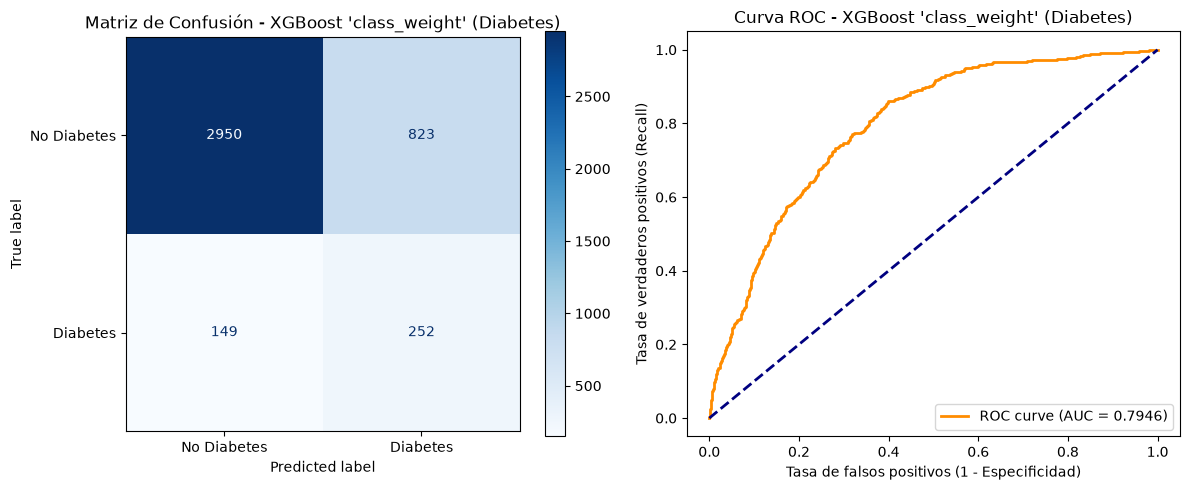

In [46]:
# ===============================================
# EVALUACIÓN XGBOOST 'class_weight' - DIABETES
# ===============================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_diab_cw = xgb_model_cw_diab.predict_proba(X_test_diab)[:, 1]
y_pred_xgb_diab_cw = xgb_model_cw_diab.predict(X_test_diab)


print("INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT (Diabetes)")
print(classification_report(y_test_diab, y_pred_xgb_diab_cw, digits=4))

# ROC-AUC
auc_xgb_diab_cw = roc_auc_score(y_test_diab, y_pred_proba_xgb_diab_cw)
print(f"ROC-AUC Score: {auc_xgb_diab_cw:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_diab_cw = confusion_matrix(y_test_diab, y_pred_xgb_diab_cw)
disp_xgb_diab_cw = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_diab_cw, display_labels=["No Diabetes", "Diabetes"])
disp_xgb_diab_cw.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost 'class_weight' (Diabetes)")

# Curva ROC
fpr_xgb_diab_cw, tpr_xgb_diab_cw, _ = roc_curve(y_test_diab, y_pred_proba_xgb_diab_cw)
axes[1].plot(fpr_xgb_diab_cw, tpr_xgb_diab_cw, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_diab_cw:.4f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost 'class_weight' (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_diab_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [47]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, xgb_model_cw_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, xgb_model_cw_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9570 | Recall test: 0.6284
Diferencia: 0.3286


INFORME DE CLASIFICACIÓN - XGBOOST 'class_weight' y 'sample_weight' (Diabetes)
              precision    recall  f1-score   support

           0     0.9478    0.7941    0.8641      3773
           1     0.2330    0.5885    0.3338       401

    accuracy                         0.7743      4174
   macro avg     0.5904    0.6913    0.5990      4174
weighted avg     0.8791    0.7743    0.8132      4174

ROC-AUC Score: 0.7835


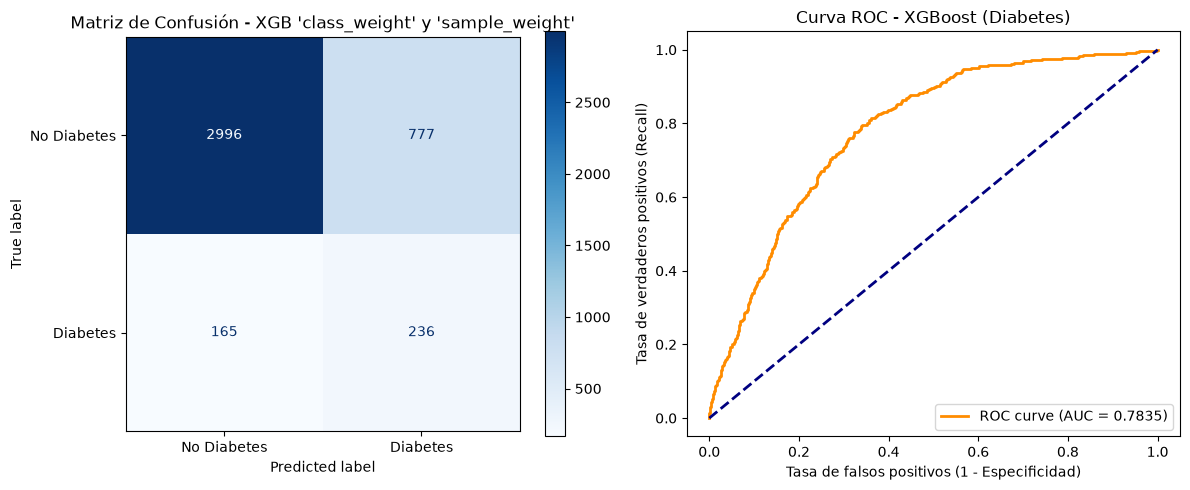

In [48]:
# ===========================================================
# EVALUACIÓN XGBOOST 'class_weight' y FACTORADULTO - DIABETES
# ===========================================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_diab = xgb_model_diab.predict_proba(X_test_diab)[:, 1]
y_pred_xgb_diab = xgb_model_diab.predict(X_test_diab)


print("INFORME DE CLASIFICACIÓN - XGBOOST 'class_weight' y 'sample_weight' (Diabetes)")
print(classification_report(y_test_diab, y_pred_xgb_diab, digits=4))

# ROC-AUC
auc_xgb_diab = roc_auc_score(y_test_diab, y_pred_proba_xgb_diab)
print(f"ROC-AUC Score: {auc_xgb_diab:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_diab = confusion_matrix(y_test_diab, y_pred_xgb_diab)
disp_xgb_diab = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_diab, display_labels=["No Diabetes", "Diabetes"])
disp_xgb_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGB 'class_weight' y 'sample_weight'")

# Curva ROC
fpr_xgb_diab, tpr_xgb_diab, _ = roc_curve(y_test_diab, y_pred_proba_xgb_diab)
axes[1].plot(fpr_xgb_diab, tpr_xgb_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_diab:.4f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_diab.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [49]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, xgb_model_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, xgb_model_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9152 | Recall test: 0.5885
Diferencia: 0.3267


INFORME DE CLASIFICACIÓN - XGBOOST SMOTE (Diabetes)
              precision    recall  f1-score   support

           0     0.9110    0.9852    0.9466      3773
           1     0.4043    0.0948    0.1535       401

    accuracy                         0.8996      4174
   macro avg     0.6576    0.5400    0.5501      4174
weighted avg     0.8623    0.8996    0.8704      4174

ROC-AUC Score: 0.8049


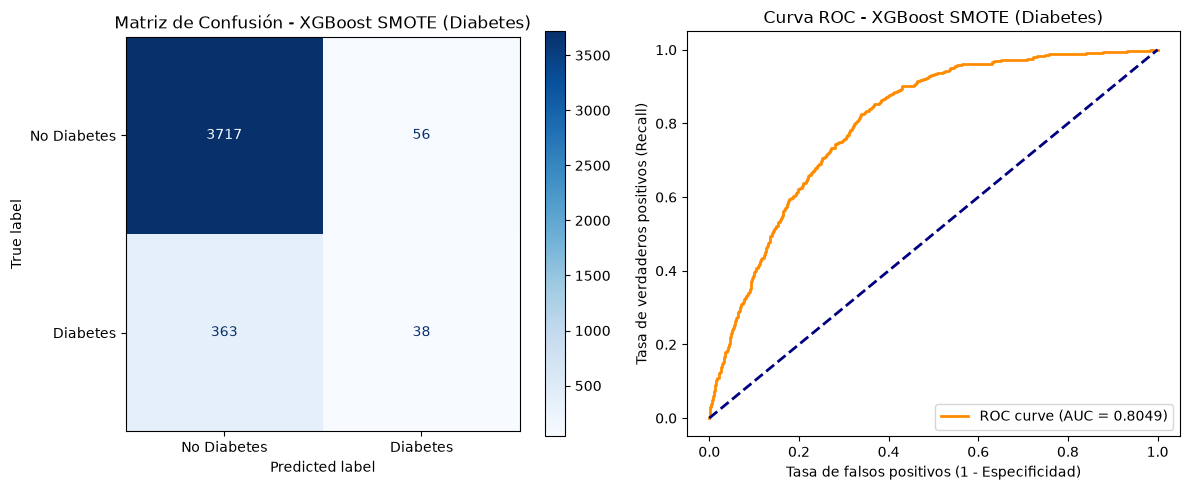

In [50]:
# ====================================
# EVALUACIÓN XGBOOST SMOTE - DIABETES
# ====================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_smote = xgb_model_smote_diab.predict_proba(X_test_diab)[:, 1]
y_pred_xgb_smote = xgb_model_smote_diab.predict(X_test_diab)


print("INFORME DE CLASIFICACIÓN - XGBOOST SMOTE (Diabetes)")
print(classification_report(y_test_diab, y_pred_xgb_smote, digits=4))

# ROC-AUC
auc_xgb_smote = roc_auc_score(y_test_diab, y_pred_proba_xgb_smote)
print(f"ROC-AUC Score: {auc_xgb_smote:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_smote = confusion_matrix(y_test_diab, y_pred_xgb_smote)
disp_xgb_smote= ConfusionMatrixDisplay(confusion_matrix=cm_xgb_smote, display_labels=["No Diabetes", "Diabetes"])
disp_xgb_smote.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost SMOTE (Diabetes)")

# Curva ROC
fpr_xgb_smote, tpr_xgb_smote, _ = roc_curve(y_test_diab, y_pred_proba_xgb_smote)
axes[1].plot(fpr_xgb_smote, tpr_xgb_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_smote:.4f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost SMOTE (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_diab_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [51]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, xgb_model_smote_diab.predict(X_train_diab))
recall_test = recall_score(y_test_diab, xgb_model_smote_diab.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.1895 | Recall test: 0.0948
Diferencia: 0.0948


INFORME DE CLASIFICACIÓN - XGBOOST Optimizado (Diabetes)
              precision    recall  f1-score   support

           0     0.9647    0.7167    0.8224      3773
           1     0.2203    0.7531    0.3409       401

    accuracy                         0.7202      4174
   macro avg     0.5925    0.7349    0.5816      4174
weighted avg     0.8932    0.7202    0.7761      4174

ROC-AUC Score: 0.8066


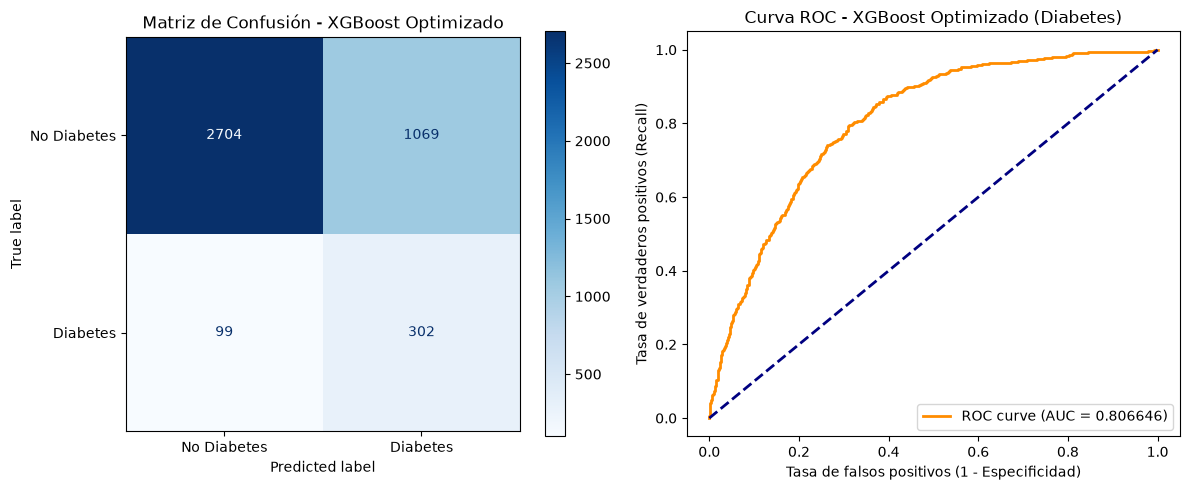

In [52]:
# ========================================
# EVALUACIÓN XGBOOST OPTIMIZADO - DIABETES
# ========================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_diab_opt = xgb_diab_opt.predict_proba(X_test_diab)[:, 1]
y_pred_xgb_diab_opt = xgb_diab_opt.predict(X_test_diab)

print("INFORME DE CLASIFICACIÓN - XGBOOST Optimizado (Diabetes)")
print(classification_report(y_test_diab, y_pred_xgb_diab_opt, digits=4))

# ROC-AUC
auc_xgb_diab_opt = roc_auc_score(y_test_diab, y_pred_proba_xgb_diab_opt)
print(f"ROC-AUC Score: {auc_xgb_diab_opt:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_diab_opt = confusion_matrix(y_test_diab, y_pred_xgb_diab_opt)
disp_xgb_diab_opt = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_diab_opt, display_labels=["No Diabetes", "Diabetes"])
disp_xgb_diab_opt.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost Optimizado")

# Curva ROC
fpr_xgb_diab_opt, tpr_xgb_diab_opt, _ = roc_curve(y_test_diab, y_pred_proba_xgb_diab_opt)
axes[1].plot(fpr_xgb_diab_opt, tpr_xgb_diab_opt, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_diab_opt:.6f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost Optimizado (Diabetes)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_diab_optimizado.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [53]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_diab, xgb_diab_opt.predict(X_train_diab))
recall_test = recall_score(y_test_diab, xgb_diab_opt.predict(X_test_diab))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8323 | Recall test: 0.7531
Diferencia: 0.0792


In [54]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

y_proba_opt = xgb_diab_opt.predict_proba(X_test_diab)[:, 1]
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
evaluacion_umbrales = []

for u in umbrales:
    y_pred_u = (y_proba_opt >= u).astype(int)

    # Extraer directamente la matriz de confusión
    tn, fp, fn, tp = confusion_matrix(y_test_diab, y_pred_u).ravel()
    report = classification_report(y_test_diab, y_pred_u, output_dict=True)

    evaluacion_umbrales.append(
        {
            "Umbral": u,
            "Recall (Sensibilidad)": round(report["1"]["recall"], 4),
            "Precisión": round(report["1"]["precision"], 4),
            "F1-Score": round(report["1"]["f1-score"], 4),
            "Falsos Negativos (FN)": int(fn),
            "Falsos Positivos (FP)": int(fp),
        }
    )

df_umbrales_corregido = pd.DataFrame(evaluacion_umbrales)
display(df_umbrales_corregido)

,Umbral,Recall (Sensibilidad),Precisión,F1-Score,Falsos Negativos (FN),Falsos Positivos (FP)
0,0.20,0.9377,0.1580,0.2704,25,2004
1,0.25,0.9127,0.1666,0.2818,35,1831
2,0.30,0.8953,0.1779,0.2968,42,1659
3,0.35,0.8753,0.1883,0.3099,50,1513
4,0.40,0.8354,0.1965,0.3181,66,1370
5,0.45,0.8030,0.2079,0.3303,79,1227
6,0.50,0.7531,0.2203,0.3409,99,1069


In [55]:
import numpy as np
from sklearn.metrics import roc_curve

# Calcular FPR, TPR y umbrales de la curva ROC
fpr, tpr, thresholds = roc_curve(y_test_diab, y_proba_opt)

# Índice de Youden: J = Sensibilidad - FPR (ya que FPR = 1 - Especificidad)
j_scores = tpr - fpr
opt_idx = np.argmax(j_scores)
opt_threshold = thresholds[opt_idx]

print(f"El umbral óptimo según el Índice de Youden es: {opt_threshold:.2f}")

El umbral óptimo según el Índice de Youden es: 0.46


# EVALUACIÓN POR MODELO

In [7]:
import pandas as pd
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score

#  Función de coloración
def colorear_metricas(val, metrica):
    if pd.isna(val):
        return ''
    
    if metrica == 'ROC-AUC Test':
        if val < 0.60: return 'background-color: #f8d7da; color: #721c24;'
        elif val < 0.70: return 'background-color: #ffeba8; color: #856404;'
        elif val < 0.80: return 'background-color: #d4edda; color: #155724;'
        else: return 'background-color: #28a745; color: white;'

    elif metrica == 'Recall Test':
        if val >= 0.80: return 'background-color: #28a745; color: white;'
        elif val >= 0.60: return 'background-color: #d4edda; color: #155724;'
        else: return 'background-color: #f8d7da; color: #721c24;'

    elif metrica == 'Precision Test':
        if val < 0.20: return 'background-color: #f8d7da; color: #721c24;'
        return ''

    elif metrica == 'F1-Score Test':
        if val < 0.50: return 'background-color: #f8d7da; color: #721c24;'
        elif val <= 0.65: return 'background-color: #ffeba8; color: #856404;'
        else: return 'background-color: #d4edda; color: #155724;'

    elif metrica == 'Dif. Recall (Train - Test)':
        mag = abs(val)
        if mag > 0.10: return 'background-color: #f8d7da; color: #721c24;'
        elif mag >= 0.05: return 'background-color: #ffeba8; color: #856404;'
        else: return 'background-color: #d4edda; color: #155724;'

    return ''

# 2. Función reutilizable para generar y estilizar la tabla
def generar_tabla_comparativa(diccionario_modelos, X_train, y_train, X_test, y_test):
    resultados = []

    for nombre, modelo in diccionario_modelos.items():
        y_pred_train = modelo.predict(X_train)
        y_pred_test = modelo.predict(X_test)
        y_proba_test = modelo.predict_proba(X_test)[:, 1] if hasattr(modelo, "predict_proba") else modelo.decision_function(X_test)
        
        acc_test = accuracy_score(y_test, y_pred_test)
        recall_train = recall_score(y_train, y_pred_train)
        recall_test = recall_score(y_test, y_pred_test)
        diff_recall = recall_train - recall_test 
        
        resultados.append({
            'Modelo': nombre,
            'Accuracy Test': round(acc_test, 4),
            'Recall Test': round(recall_test, 4),
            'Dif. Recall (Train - Test)': round(diff_recall, 4),
            'Precision Test': round(precision_score(y_test, y_pred_test), 4),
            'F1-Score Test': round(f1_score(y_test, y_pred_test), 4),
            'ROC-AUC Test': round(roc_auc_score(y_test, y_proba_test), 4)
        })

    df = pd.DataFrame(resultados).sort_values(by='ROC-AUC Test', ascending=False).reset_index(drop=True)

    styler = df.style.format({
        'Accuracy Test': '{:.4f}',
        'Recall Test': '{:.4f}',
        'Dif. Recall (Train - Test)': '{:.4f}',
        'Precision Test': '{:.4f}',
        'F1-Score Test': '{:.4f}',
        'ROC-AUC Test': '{:.4f}'
    })

    for col in df.columns:
        if col != 'Modelo':
            styler = styler.map(lambda v, c=col: colorear_metricas(v, c), subset=[col])

    return styler

In [9]:
import os
import dataframe_image as dfi

# 1. Definir los modelos
modelos_rl_diab = {
    'Regresión Logística (Class Weight)': reg_log_diab_class_weight,
    'Regresión Logística (Class Weight + Sample Weight)': reg_log_diab,
    'Regresión Logística (SMOTE)': reg_log_diab_smote
}

# 2. Generar y guardar la tabla en una variable
tabla_estilizada = generar_tabla_comparativa(modelos_rl_diab, X_train_diab, y_train_diab, X_test_diab, y_test_diab)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_regresion_logistica_diabetes.png'),
    table_conversion="matplotlib")

# Instalar el motor necesario para exportar a Excel
%pip install openpyxl -q

tabla_estilizada.to_excel(
    os.path.join('../reports/tables/comparativa_regresion_logistica.diab.xlsx'),
    index=False
)
# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,Regresión Logística (Class Weight),0.7199,0.7830,0.0081,0.2249,0.3495,0.8086
1,Regresión Logística (Class Weight + Sample Weight),0.6782,0.8254,0.0162,0.2064,0.3302,0.8068
2,Regresión Logística (SMOTE),0.7319,0.7531,0.0168,0.2284,0.3506,0.8068


In [10]:
modelos_rf_diab = {
    'Random Forest (Class Weight)': rf_diab_class_weight,
    'Random Forest (Class Weight + Sample Weight)': rf_diab,
    'Random Forest (SMOTE)': rf_smote_diab,
    'Random Forest c/ pesos dinámicos': rf_subsample,
    'Balanced Random Forest': brf_diabetes,
    'Balanced Random Forest (Sample Weight)': brf_sample_weight_diab,
    'Balanced Random Forest Optimizado': brf_opt_gridsearch
    }

# Generar la tabla coloreada reutilizando la función
tabla_estilizada = generar_tabla_comparativa(modelos_rf_diab, X_train_diab, y_train_diab, X_test_diab, y_test_diab)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_random_forest_diabetes.png'),
    table_conversion="matplotlib")

tabla_estilizada.to_excel(
    os.path.join('../reports/tables/comparativa_random_forest_diabetes.xlsx'),
    index=False)

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,Balanced Random Forest,0.7770,0.6459,0.3541,0.2471,0.3575,0.8024
1,Balanced Random Forest (Sample Weight),0.6967,0.7756,0.1365,0.2091,0.3294,0.7977
2,Random Forest (Class Weight + Sample Weight),0.8747,0.2519,0.7419,0.3117,0.2786,0.7964
3,Balanced Random Forest Optimizado,0.5884,0.8903,0.1097,0.1758,0.2936,0.7958
4,Random Forest (Class Weight),0.8920,0.1721,0.8279,0.3670,0.2343,0.7944
5,Random Forest (SMOTE),0.8912,0.1372,0.1615,0.3374,0.1950,0.7937
6,Random Forest c/ pesos dinámicos,0.7762,0.5960,0.2874,0.2364,0.3385,0.7900


In [11]:
modelos_svm_diab = {
    'SVM (Class Weight)': svm_diab_cw,
    'SVM (Class Weight + Sample Weight)': svm_diab,
    'SVM (SMOTE)': svm_diab_smote,
    'SVM Optimizado': svm_diab_opt
}

tabla_estilizada = generar_tabla_comparativa(modelos_svm_diab, X_train_diab, y_train_diab, X_test_diab, y_test_diab)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_svm_diabetes.png'),
    table_conversion="matplotlib")

tabla_estilizada.to_excel(
    os.path.join('../reports/tables/comparativa_svm_diabetes.xlsx'),
    index=False)

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,SVM Optimizado,0.6989,0.7855,0.0530,0.2120,0.3339,0.8031
1,SVM (Class Weight),0.7508,0.6509,0.3061,0.2248,0.3342,0.7856
2,SVM (Class Weight + Sample Weight),0.7690,0.6060,0.2893,0.2316,0.3352,0.7854
3,SVM (SMOTE),0.8491,0.3716,0.3678,0.2827,0.3211,0.7637


In [12]:
modelos_xgb_diab ={
    'XGBoost (Class Weight)': xgb_model_cw_diab,
    'XGBoost (Class Weight + Sample Weight)': xgb_model_diab,
    'XGBoost (SMOTE)': xgb_model_smote_diab,
    'XGBoost Optimizado': xgb_diab_opt
}


# 2. Generar y guardar la tabla en una variable
tabla_estilizada = generar_tabla_comparativa(modelos_xgb_diab, X_train_diab, y_train_diab, X_test_diab, y_test_diab)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_xgboost_diabetes.png'),
    table_conversion="matplotlib")

tabla_estilizada.to_excel(
    os.path.join('../reports/tables/comparativa_xgboost_diabetes.xlsx'),
    index=False)


# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,XGBoost Optimizado,0.7202,0.7531,0.0792,0.2203,0.3409,0.8066
1,XGBoost (SMOTE),0.8996,0.0948,0.0948,0.4043,0.1535,0.8049
2,XGBoost (Class Weight),0.7671,0.6284,0.3286,0.2344,0.3415,0.7946
3,XGBoost (Class Weight + Sample Weight),0.7743,0.5885,0.3267,0.2330,0.3338,0.7835


# TABLA COMPARATIVA DE MEJORES RESULTADOS POR MODELO

In [13]:
tabla_comparativa_final = {
    'Regresión Logística (Class Weight + Sample Weight)': reg_log_diab,
    'Balanced Random Forest Optimizado': brf_opt_gridsearch,
    'SVM Optimizado': svm_diab_opt,
    'XGBoost Optimizado': xgb_diab_opt
}

# 2. Generar y guardar la tabla en una variable
tabla_estilizada = generar_tabla_comparativa(tabla_comparativa_final, X_train_diab, y_train_diab, X_test_diab, y_test_diab)
# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'tabla_comparativa_final_diabetes.png'),
    table_conversion="matplotlib")

tabla_estilizada.to_excel(
    os.path.join('../reports/tables/comparativa_final_diabetes.xlsx'),
    index=False)

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,Regresión Logística (Class Weight + Sample Weight),0.6782,0.8254,0.0162,0.2064,0.3302,0.8068
1,XGBoost Optimizado,0.7202,0.7531,0.0792,0.2203,0.3409,0.8066
2,SVM Optimizado,0.6989,0.7855,0.0530,0.2120,0.3339,0.8031
3,Balanced Random Forest Optimizado,0.5884,0.8903,0.1097,0.1758,0.2936,0.7958


In [62]:
# cargar dataframe renombrado 

df_adulto = pd.read_csv("../data/processed/ESdE_2023_renombrado.csv")

In [63]:
# ==============================================================================
# EVALUACIÓN DE DETECCIÓN DE PACIENTES SIN DIAGNÓSTICO PERO CON SÍNTOMAS
# ==============================================================================

# 1. Obtenemos los índices de las personas de TEST que NO tienen diagnóstico médico formal
# (Asumiendo que y_test_diab == 0 son los no diagnosticados en tu split)
idx_sin_diag = y_test_diab[y_test_diab.values.ravel() == 0].index

# 2. Hacemos la predicción del modelo optimizado solo para este grupo sin diagnóstico
# Usamos las variables X_test correspondientes a esos índices
preds_sin_diag = xgb_diab_opt.predict(X_test_diab.loc[idx_sin_diag])

# 3. Cruzamos con la variable 'Diabetes_Ultimos_12m' rescatada del dataframe original
# Filtramos solo los que pertenecían a test y contestaron SÍ (1.0) en los últimos 12 meses
sintomas_12m_sin_diag = df_adulto.loc[idx_sin_diag, "Diabetes_Ultimos_12m"] == 1.0

# 4. Evaluamos a cuántos de ellos el modelo los clasificó como "En Riesgo" (Predicción == 1)
total_casos_ocultos = sintomas_12m_sin_diag.sum()
detectados_por_modelo = (preds_sin_diag[sintomas_12m_sin_diag] == 1).sum()

porcentaje_exito = (detectados_por_modelo / total_casos_ocultos * 100) if total_casos_ocultos > 0 else 0

# Imprimir resultados para la tesis
print("--- EVALUACIÓN DE CAPACIDAD DE TAMIZAJE RECONSTRUIDA ---")
print(f"Total de personas sin diagnóstico pero con síntomas/controles en 12m (en Test): {total_casos_ocultos}")
print(f"Casos que el modelo XGBoost logró clasificar 'EN RIESGO': {detectados_por_modelo}")
print(f"Efectividad de captura sobre el subdiagnóstico: {porcentaje_exito:.2f}%")

--- EVALUACIÓN DE CAPACIDAD DE TAMIZAJE RECONSTRUIDA ---
Total de personas sin diagnóstico pero con síntomas/controles en 12m (en Test): 342
Casos que el modelo XGBoost logró clasificar 'EN RIESGO': 94
Efectividad de captura sobre el subdiagnóstico: 27.49%
